# 00 · Final End-to-End Pipeline
**Team:** Abdulrhman · Skkinner · Sulaiman Allumaylim · Ahmed Alluqmani

Insurance Risk Scoring Model: notebooks 01–04 merged in order. Runs top to bottom (Restart & Run All).

> This notebook only **shows** the pipeline. It does not overwrite the saved models; they come from the dev notebooks in `notebooks/dev/`.

In [1]:
# ===== SHARED SETUP (same in every notebook — don't change without telling the team) =====
import os, sys

# In Colab: clone the repo and move into it
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/Ahmed-log11/Deep_Learning_Project.git"
    if not os.path.exists("Deep_Learning_Project"):
        !git clone {REPO_URL}
    %cd Deep_Learning_Project
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # running locally from notebooks/

import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Paths
RAW_CSV          = "data/raw/Car_Insurance_Claim.csv"
PROCESSED_DIR    = "data/processed"
MODELS_DIR       = "models"
FIGURES_DIR      = "reports/figures"
PREPROCESSOR_PKL = f"{MODELS_DIR}/preprocessor.pkl"
BEST_MODEL       = f"{MODELS_DIR}/best_model.keras"
TARGET           = "OUTCOME"

def load_splits():
    """Load the frozen splits saved by notebook 01."""
    names = ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test"]
    return [np.load(f"{PROCESSED_DIR}/{n}.npy") for n in names]


## 1. Problem Definition

Given a customer's profile (age, driving experience, income, vehicle, driving history...), predict whether they will make an insurance claim (`OUTCOME`: 0 = no claim, 1 = claim).

- **Dataset:** [Car Insurance Data (Kaggle)](https://www.kaggle.com/datasets/sagnik1511/car-insurance-data), 10,000 customers, 19 columns, ~31% claim.
- **Model:** feed-forward ANN (Keras) → claim probability.
- **Main metric:** ROC-AUC (does not depend on the threshold). Precision, Recall and F1 are also reported, because the classes are imbalanced and accuracy alone is misleading.

## 2. Data & Preprocessing
*From notebook 01.*

#### Decisions at a glance
| Topic | Decision |
|---|---|
| Duplicates | Removed **before** splitting (exact rows, repeated IDs, identical profile + outcome). Otherwise the same customer could land in train *and* test and inflate the metrics. |
| Missing values | Rows with missing values are **removed** (`MISSING_STRATEGY = "drop"`). Set it to `"impute"` to keep them instead — the imputers inside the saved preprocessor are then fitted on **train only**. |
| Leakage | `ID` is dropped (identifier). Every other feature is audited (identifier test, target-name test, single-feature AUC) and its availability at quote time is reviewed in section 3.6. |
| Pipeline leakage | Scaler / encoders / imputers are **fitted on the training split only**, then applied to val/test (section 5). |
| Output contract | `X_*.npy`, `y_*.npy`, `class_weights.json`, `feature_names.json`, `preprocessor_meta.json` in `data/processed/`; `preprocessor.pkl` in `models/`. |

In [2]:
# ===== Notebook-01 imports & settings (NOT part of the shared setup) =====
import json, glob, shutil, warnings
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
for d in (PROCESSED_DIR, MODELS_DIR, FIGURES_DIR):
    os.makedirs(d, exist_ok=True)

ID_COL           = "ID"
MISSING_STRATEGY = "drop"        # "drop" = remove rows with missing values | "impute" = keep, impute (train-fitted)
TEST_SIZE        = 0.15
VAL_SIZE         = 0.15          # share of the WHOLE dataset -> 70 / 15 / 15
LEAK_AUC         = 0.85          # single-feature AUC above this is "too good to be true"
DROP_SENSITIVE   = False         # True -> also drop RACE and GENDER (fairness); kept by default, see section 3.6
SENSITIVE_COLS   = ["RACE", "GENDER"]

# Ordered categories (low -> high). A column whose values don't match is automatically treated as nominal (one-hot).
ORDINAL_ORDER = {
    "AGE":                ["16-25", "26-39", "40-64", "65+"],
    "DRIVING_EXPERIENCE": ["0-9y", "10-19y", "20-29y", "30y+"],
    "EDUCATION":          ["none", "high school", "university"],
    "INCOME":             ["poverty", "working class", "middle class", "upper class"],
    "VEHICLE_YEAR":       ["before 2015", "after 2015"],
}
NOMINAL_CODES = ["POSTAL_CODE"]   # numeric-looking codes that are really categories (the number has no magnitude)
RANGE_RULES   = {"CREDIT_SCORE": (0, 1), "ANNUAL_MILEAGE": (0, None)}   # (min, max) sanity limits

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/{name}", dpi=150, bbox_inches="tight")
    plt.show()

### 1. Load Data

In [3]:
def resolve_raw_csv(path=RAW_CSV):
    """Return the raw CSV path. If the file is missing, try downloading it with kagglehub (works in Colab)."""
    if os.path.exists(path):
        return path
    try:
        import kagglehub
        folder = kagglehub.dataset_download("sagnik1511/car-insurance-data")
        hits = [p for p in glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
                if os.path.basename(p).lower() == os.path.basename(path).lower()]
        if not hits:
            raise FileNotFoundError(f"{os.path.basename(path)} not in downloaded folder {folder}")
        os.makedirs(os.path.dirname(path), exist_ok=True)
        shutil.copy(hits[0], path)
        return path
    except Exception as e:
        raise FileNotFoundError(
            f"'{path}' not found. Download the CSV from https://www.kaggle.com/datasets/sagnik1511/car-insurance-data "
            f"and place it in data/raw/  (automatic download failed: {e})")

raw = pd.read_csv(resolve_raw_csv())
print(f"Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw data: 10,000 rows x 19 columns


,ID,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,VEHICLE_YEAR,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,VEHICLE_TYPE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,1.0,after 2015,0.0,1.0,10238,12000.0,sedan,0,0,0,0.0
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,0.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,0,1.0
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,1.0,before 2015,0.0,0.0,10238,11000.0,sedan,0,0,0,0.0
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,1.0,before 2015,0.0,1.0,32765,11000.0,sedan,0,0,0,0.0
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,1.0,before 2015,0.0,0.0,32765,12000.0,sedan,2,0,1,1.0


**Light standardisation** (no rows are removed here): trim/upper-case column names, trim/lower-case text values, turn empty strings into real missing values.

In [4]:
df = raw.copy()
df.columns = df.columns.str.strip().str.upper()
assert TARGET in df.columns, f"Target column {TARGET} not found. Columns: {list(df.columns)}"

text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    df[c] = df[c].str.strip().str.lower().replace("", np.nan)

print("Text columns standardised:", text_cols)
df.info()

Text columns standardised: ['AGE', 'GENDER', 'RACE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'VEHICLE_YEAR', 'VEHICLE_TYPE']
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   10000 non-null  int64  
 1   AGE                  10000 non-null  str    
 2   GENDER               10000 non-null  str    
 3   RACE                 10000 non-null  str    
 4   DRIVING_EXPERIENCE   10000 non-null  str    
 5   EDUCATION            10000 non-null  str    
 6   INCOME               10000 non-null  str    
 7   CREDIT_SCORE         9018 non-null   float64
 8   VEHICLE_OWNERSHIP    10000 non-null  float64
 9   VEHICLE_YEAR         10000 non-null  str    
 10  MARRIED              10000 non-null  float64
 11  CHILDREN             10000 non-null  float64
 12  POSTAL_CODE          10000 non-null  int64  
 13  ANNUAL_MILEAGE    

### 2. EDA

#### 2.1 Column types & overview

In [5]:
def infer_groups(d):
    """Split feature columns into ordinal / nominal / binary / numeric groups (ID and target excluded)."""
    feats = [c for c in d.columns if c not in (ID_COL, TARGET)]
    ordinal = {c: o for c, o in ORDINAL_ORDER.items()
               if c in feats and set(d[c].dropna().astype(str)) <= set(o)}
    rest    = [c for c in feats if c not in ordinal]
    nominal = [c for c in rest if c in NOMINAL_CODES or not pd.api.types.is_numeric_dtype(d[c])]
    binary  = [c for c in rest if c not in nominal and set(d[c].dropna().unique()) <= {0, 1}]
    numeric = [c for c in rest if c not in nominal + binary]
    return {"ordinal": ordinal, "nominal": nominal, "binary": binary, "numeric": numeric}

groups = infer_groups(df)
for k, v in groups.items():
    print(f"{k:8s}:", list(v))
fallback = [c for c in ORDINAL_ORDER if c in df.columns and c not in groups["ordinal"]]
if fallback:
    print("\n⚠️ Ordinal order does not match the data for", fallback, "-> treated as nominal (one-hot). Observed:",
          {c: sorted(df[c].dropna().unique().tolist()) for c in fallback})

overview = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(), "n_missing": df.isna().sum()})
overview

ordinal : ['AGE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'VEHICLE_YEAR']
nominal : ['GENDER', 'RACE', 'POSTAL_CODE', 'VEHICLE_TYPE']
binary  : ['VEHICLE_OWNERSHIP', 'MARRIED', 'CHILDREN']
numeric : ['CREDIT_SCORE', 'ANNUAL_MILEAGE', 'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS']


,dtype,n_unique,n_missing
ID,int64,10000,0
AGE,str,4,0
GENDER,str,2,0
RACE,str,2,0
DRIVING_EXPERIENCE,str,4,0
EDUCATION,str,3,0
INCOME,str,4,0
CREDIT_SCORE,float64,9018,982
VEHICLE_OWNERSHIP,float64,2,0
VEHICLE_YEAR,str,2,0


In [6]:
display(df.describe().T)
display(df.describe(exclude="number").T if df.select_dtypes(exclude="number").shape[1] else "no text columns")

,count,mean,std,min,25%,50%,75%,max
ID,10000.0,500521.906800,290030.768758,101.000000,249638.500000,501777.000000,753974.500000,999976.000000
CREDIT_SCORE,9018.0,0.515813,0.137688,0.053358,0.417191,0.525033,0.618312,0.960819
VEHICLE_OWNERSHIP,10000.0,0.697000,0.459578,0.000000,0.000000,1.000000,1.000000,1.000000
MARRIED,10000.0,0.498200,0.500022,0.000000,0.000000,0.000000,1.000000,1.000000
CHILDREN,10000.0,0.688800,0.463008,0.000000,0.000000,1.000000,1.000000,1.000000
POSTAL_CODE,10000.0,19864.548400,18915.613855,10238.000000,10238.000000,10238.000000,32765.000000,92101.000000
ANNUAL_MILEAGE,9043.0,11697.003207,2818.434528,2000.000000,10000.000000,12000.000000,14000.000000,22000.000000
SPEEDING_VIOLATIONS,10000.0,1.482900,2.241966,0.000000,0.000000,0.000000,2.000000,22.000000
DUIS,10000.0,0.239200,0.554990,0.000000,0.000000,0.000000,0.000000,6.000000
PAST_ACCIDENTS,10000.0,1.056300,1.652454,0.000000,0.000000,0.000000,2.000000,15.000000


,count,unique,top,freq
AGE,10000,4,26-39,3063
GENDER,10000,2,female,5010
RACE,10000,2,majority,9012
DRIVING_EXPERIENCE,10000,4,0-9y,3530
EDUCATION,10000,3,high school,4157
INCOME,10000,4,upper class,4336
VEHICLE_YEAR,10000,2,before 2015,6967
VEHICLE_TYPE,10000,2,sedan,9523


#### 2.2 Target distribution

         count   share
OUTCOME               
0.0       6867  0.6867
1.0       3133  0.3133


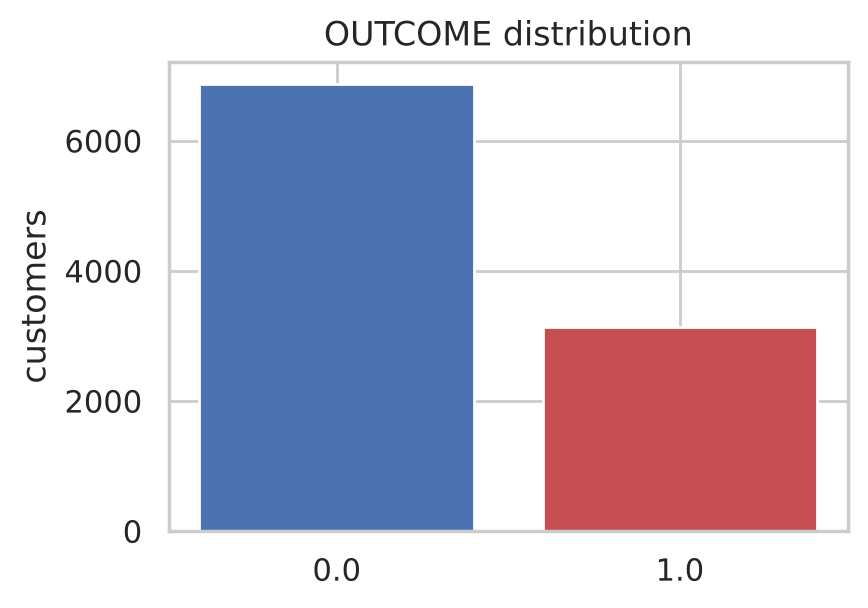

In [7]:
target_counts = df[TARGET].value_counts(dropna=False).sort_index()
print(pd.DataFrame({"count": target_counts, "share": (target_counts / len(df)).round(4)}))

fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(target_counts.index.astype(str), target_counts.values, color=["#4C72B0", "#C44E52"][:len(target_counts)])
ax.set_title(f"{TARGET} distribution"); ax.set_ylabel("customers")
savefig("01_target_distribution.png")

#### 2.3 Missing values (before cleaning)

,missing,pct
CREDIT_SCORE,982,9.82
ANNUAL_MILEAGE,957,9.57


Rows with at least one missing value: 1,851 (18.5% of the data)


,claim_rate_if_missing,claim_rate_if_present
CREDIT_SCORE,0.310,0.314
ANNUAL_MILEAGE,0.338,0.311


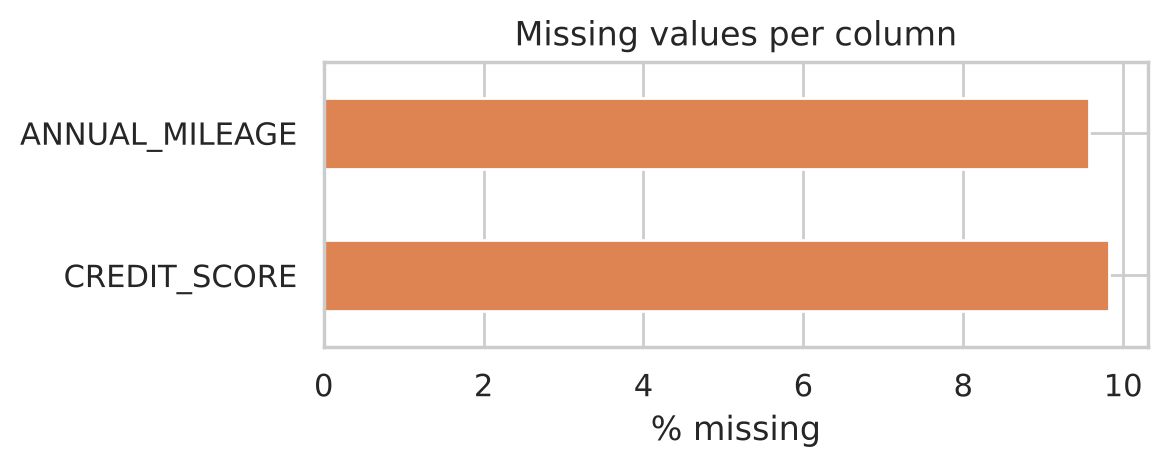

In [8]:
miss = df.isna().sum().to_frame("missing")
miss["pct"] = (miss["missing"] / len(df) * 100).round(2)
miss = miss[miss["missing"] > 0].sort_values("missing", ascending=False)

if miss.empty:
    print("No missing values.")
else:
    display(miss)
    print(f"Rows with at least one missing value: {df.isna().any(axis=1).sum():,} "
          f"({df.isna().any(axis=1).mean():.1%} of the data)")

    # Is missingness related to the outcome? (if the claim rates differ a lot, dropping rows would bias the data)
    rel = pd.DataFrame({
        c: {"claim_rate_if_missing": df.loc[df[c].isna(), TARGET].mean(),
            "claim_rate_if_present": df.loc[df[c].notna(), TARGET].mean()}
        for c in miss.index}).T.round(3)
    display(rel)

    ax = miss["pct"].plot.barh(figsize=(6, 0.5 * len(miss) + 1.5), color="#DD8452")
    ax.set_xlabel("% missing"); ax.set_title("Missing values per column")
    savefig("02_missing_values.png")

#### 2.4 Numeric feature distributions (by outcome)

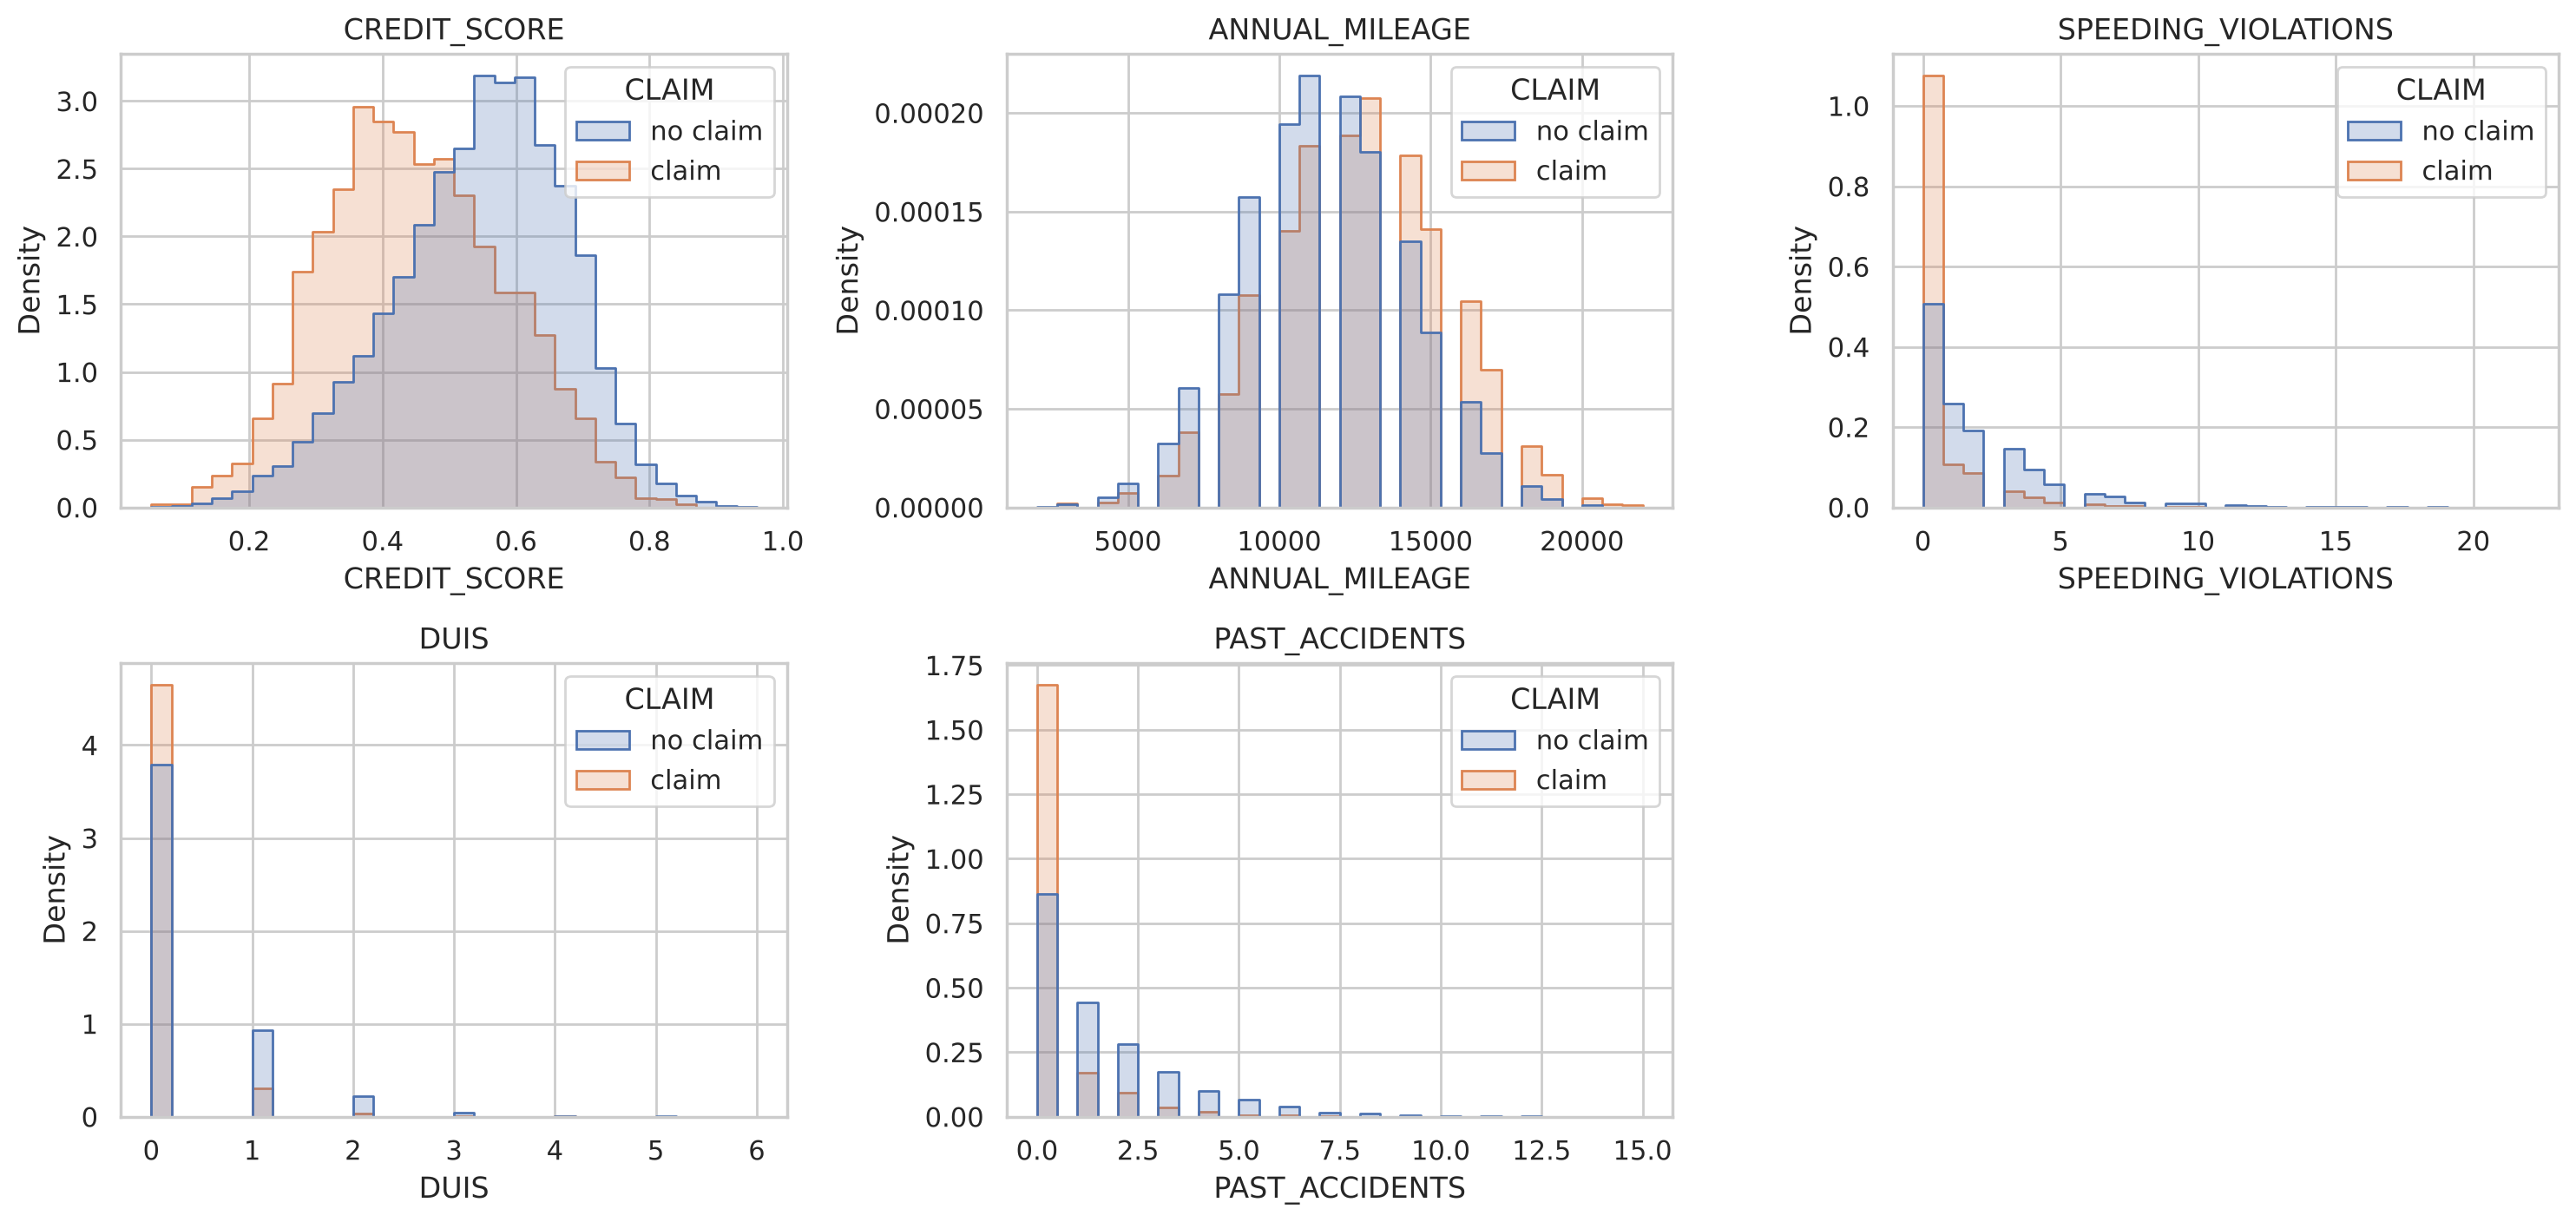

In [9]:
num_cols = groups["numeric"]
if num_cols:
    tmp = df.assign(CLAIM=df[TARGET].map({0: "no claim", 1: "claim"}))
    ncols = min(3, len(num_cols)); nrows = int(np.ceil(len(num_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.6 * nrows), squeeze=False)
    for ax, c in zip(axes.ravel(), num_cols):
        sns.histplot(data=tmp, x=c, hue="CLAIM", bins=30, element="step", stat="density", common_norm=False, ax=ax)
        ax.set_title(c)
    for ax in axes.ravel()[len(num_cols):]:
        ax.set_visible(False)
    savefig("03_numeric_distributions.png")

#### 2.5 Claim rate by category

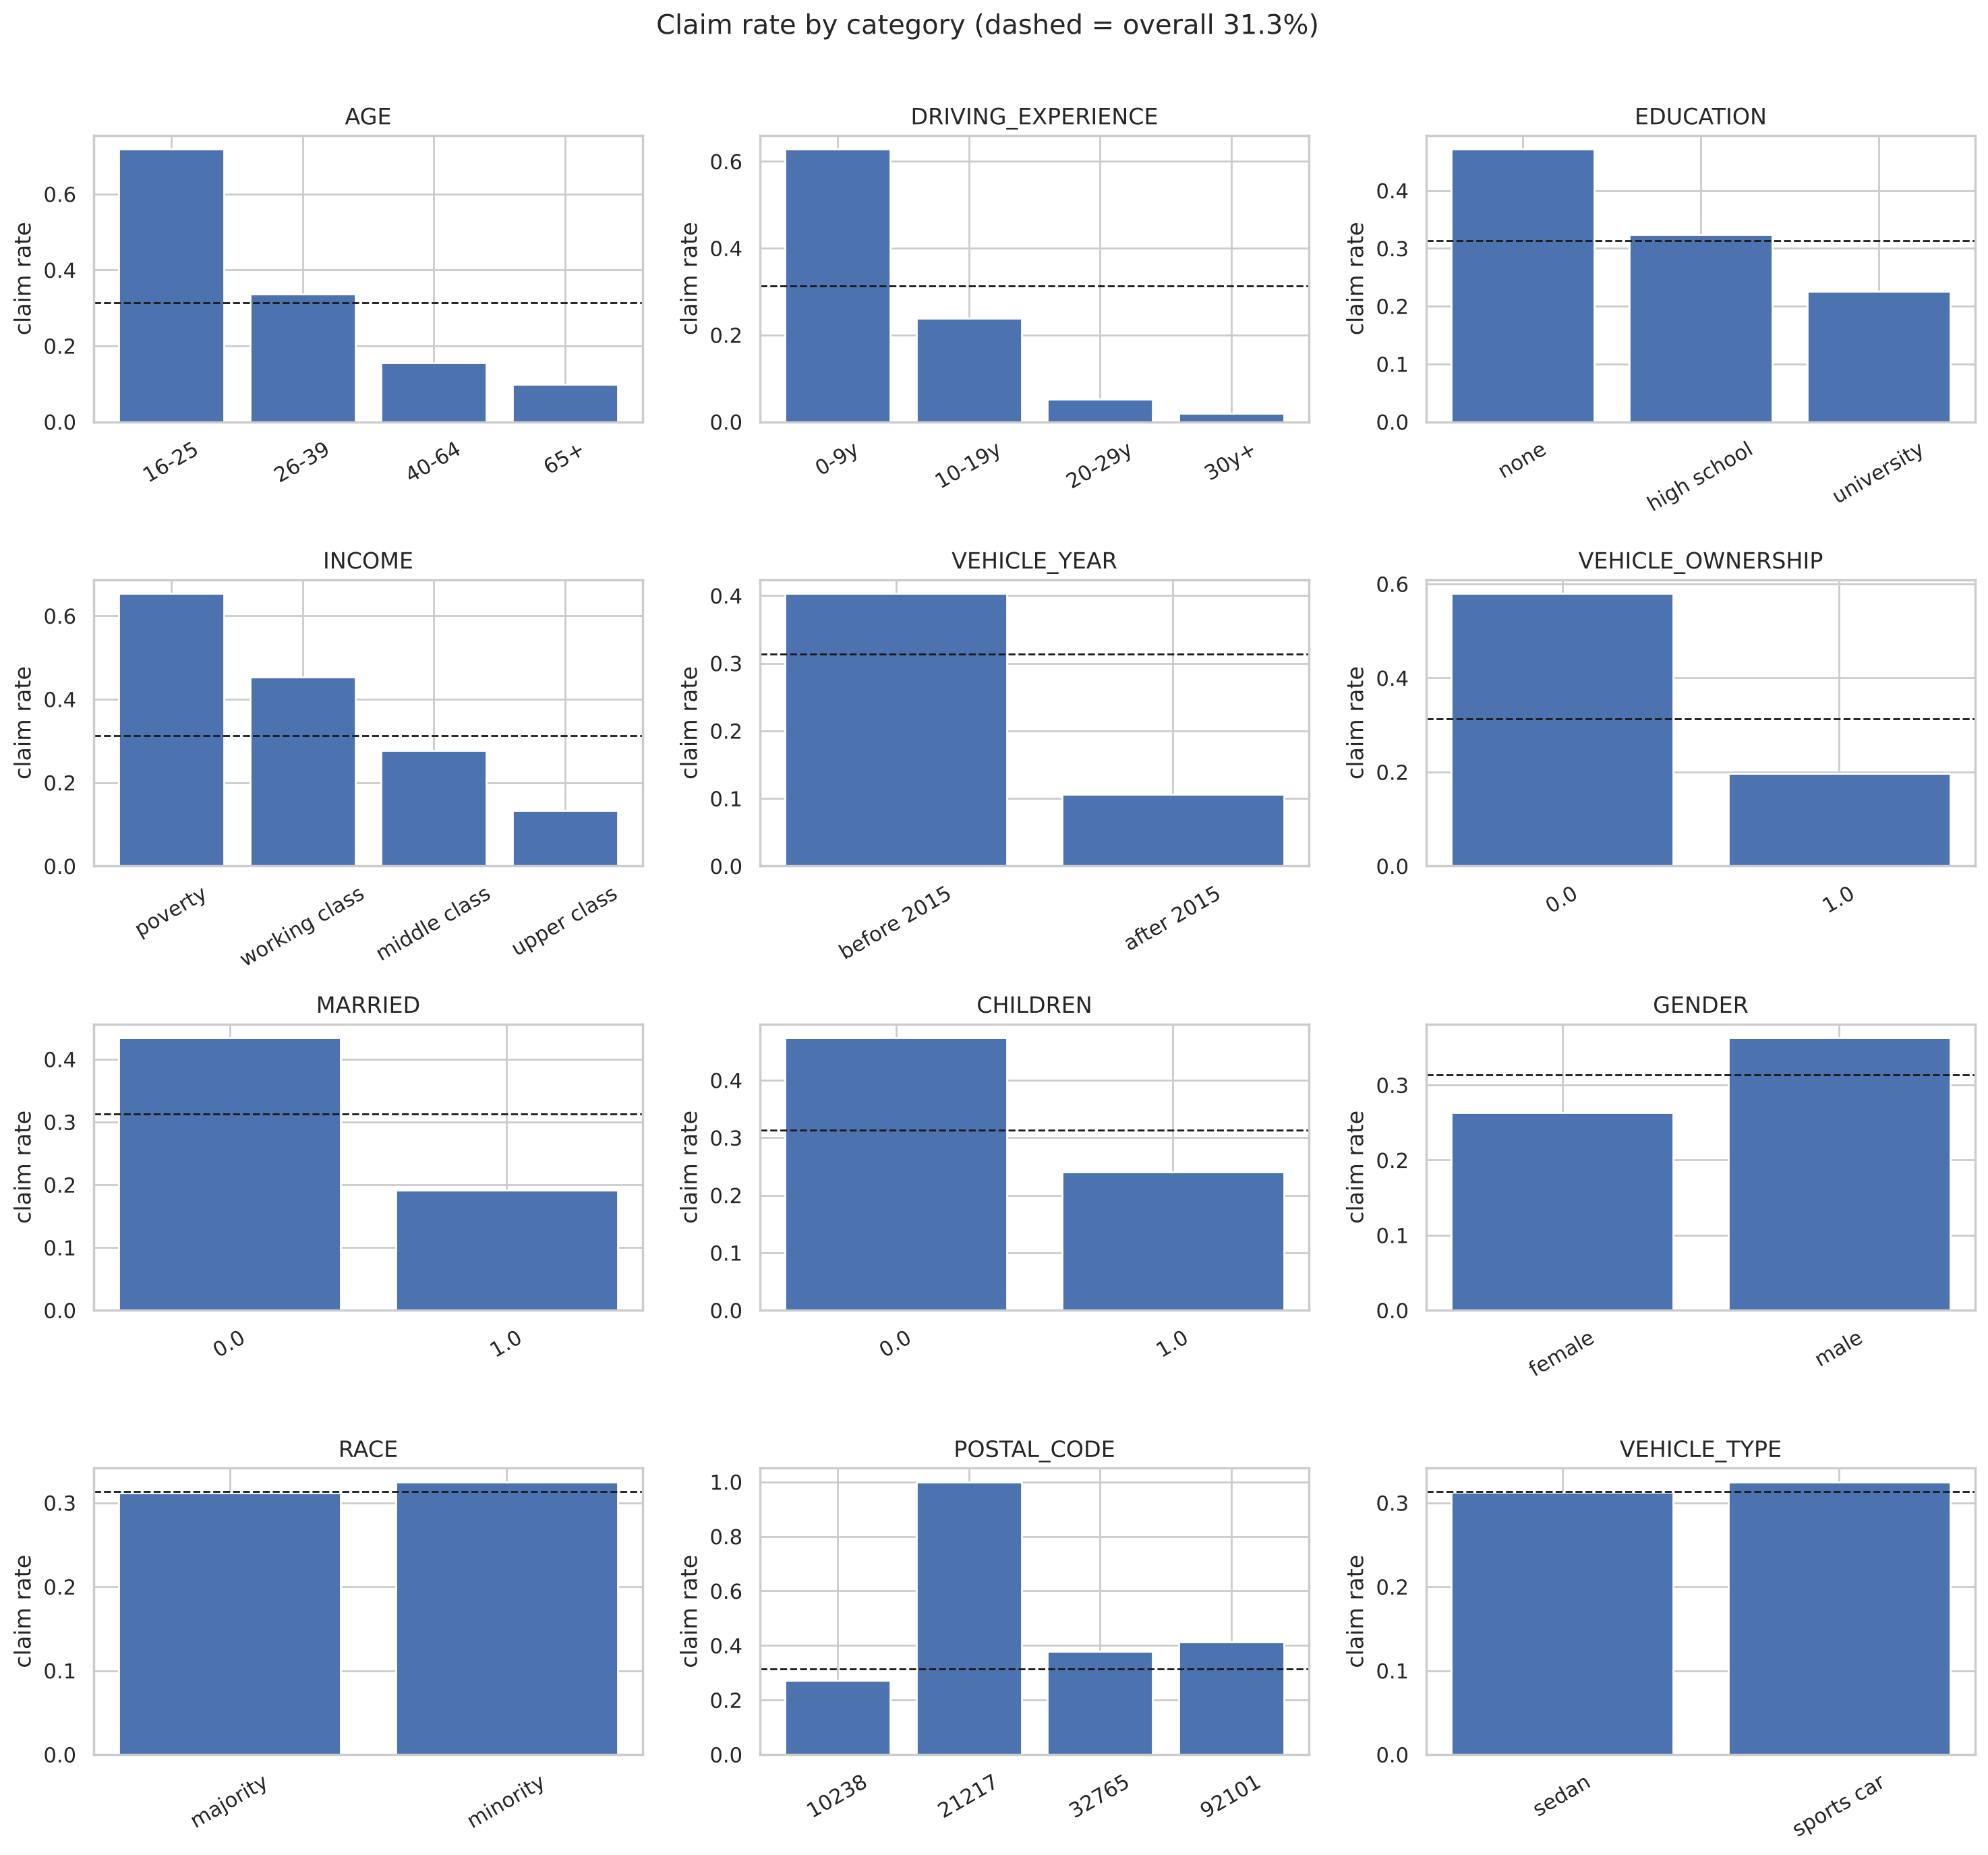

In [10]:
cat_cols = list(groups["ordinal"]) + groups["binary"] + groups["nominal"]
overall = df[TARGET].mean()
ncols = 3; nrows = int(np.ceil(len(cat_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.4 * nrows), squeeze=False)
for ax, c in zip(axes.ravel(), cat_cols):
    rate = df.groupby(c)[TARGET].mean()
    if c in groups["ordinal"]:
        rate = rate.reindex([k for k in groups["ordinal"][c] if k in rate.index])
    ax.bar(rate.index.astype(str), rate.values, color="#4C72B0")
    ax.axhline(overall, ls="--", c="k", lw=1)
    ax.set_title(c); ax.set_ylabel("claim rate"); ax.tick_params(axis="x", rotation=30)
for ax in axes.ravel()[len(cat_cols):]:
    ax.set_visible(False)
fig.suptitle(f"Claim rate by category (dashed = overall {overall:.1%})", y=1.01)
savefig("04_claim_rate_by_category.png")

#### 2.6 Correlations (Spearman, ordinal features coded by their order)

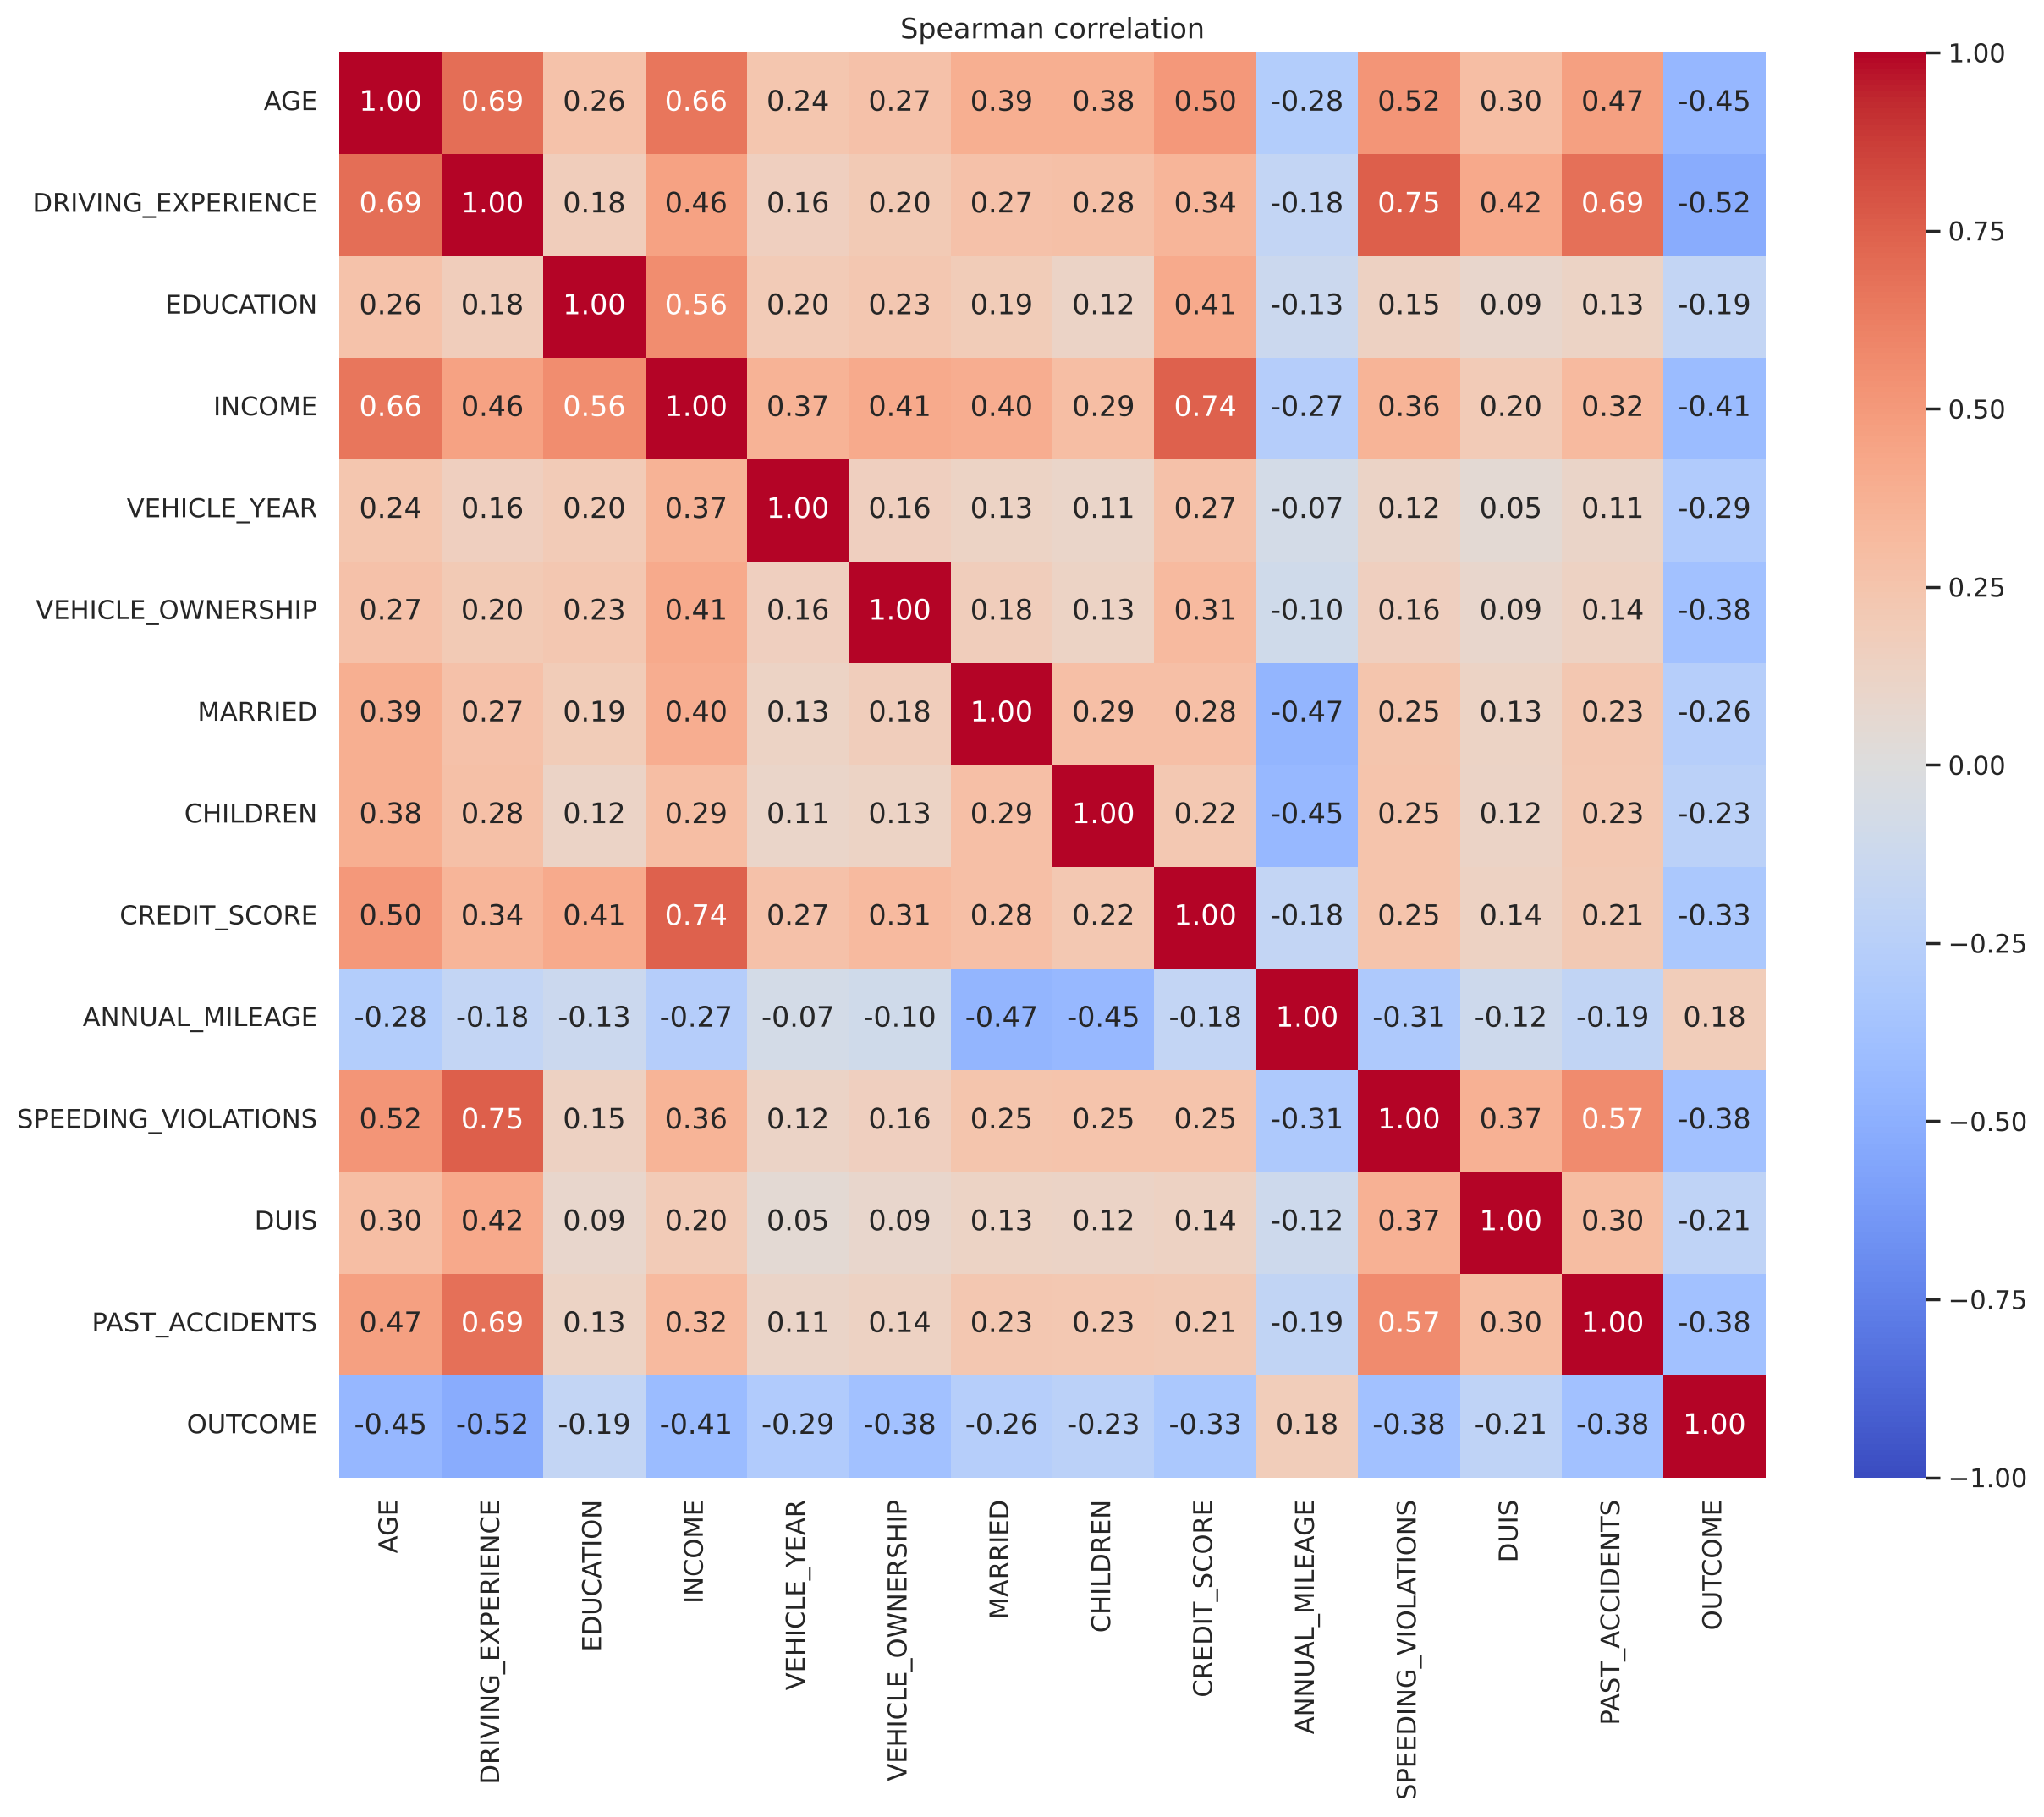

Correlation with target:
DRIVING_EXPERIENCE    -0.519
AGE                   -0.448
INCOME                -0.415
VEHICLE_OWNERSHIP     -0.379
PAST_ACCIDENTS        -0.378
SPEEDING_VIOLATIONS   -0.377
CREDIT_SCORE          -0.327
VEHICLE_YEAR          -0.294
MARRIED               -0.262
CHILDREN              -0.233
DUIS                  -0.205
EDUCATION             -0.186
ANNUAL_MILEAGE         0.183

Feature pairs with |rho| > 0.8 (multicollinearity, not leakage): none


In [11]:
def to_codes(d):
    out = d.copy()
    for c, order in groups["ordinal"].items():
        out[c] = d[c].map({v: i for i, v in enumerate(order)})
    return out

corr_cols = list(groups["ordinal"]) + groups["binary"] + groups["numeric"] + [TARGET]
corr = to_codes(df)[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(0.7 * len(corr_cols) + 3, 0.6 * len(corr_cols) + 2.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation")
savefig("05_correlation_heatmap.png")

print("Correlation with target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
strong = pairs[(pairs.abs() > 0.8) & ~pairs.index.get_level_values(1).isin([TARGET])]
print("\nFeature pairs with |rho| > 0.8 (multicollinearity, not leakage):",
      "none" if strong.empty else "")
if not strong.empty:
    print(strong.round(3).to_string())

### 3. Missing Values & Cleaning

In [12]:
cleaning_log = {"rows_raw": int(len(raw)), "rows_after_standardisation": int(len(df))}

#### 3.1 Duplicates

In [13]:
feat_cols_all = [c for c in df.columns if c != ID_COL]            # features + target, without the ID
feat_only     = [c for c in feat_cols_all if c != TARGET]

dup_report = {
    "exact duplicate rows (all columns)":                   int(df.duplicated().sum()),
    "repeated IDs":                                         int(df[ID_COL].duplicated().sum()) if ID_COL in df else 0,
    "identical profile + outcome (ignoring ID), all values present": int((df.duplicated(subset=feat_cols_all) & df[feat_cols_all].notna().all(axis=1)).sum()),
    "identical profile + outcome (ignoring ID), only because of shared NaNs": int((df.duplicated(subset=feat_cols_all) & df[feat_cols_all].isna().any(axis=1)).sum()),
    "identical profile but DIFFERENT outcome (groups)":     int(df.groupby(feat_only, dropna=False)[TARGET].nunique().gt(1).sum()),
}
display(pd.Series(dup_report, name="count").to_frame())

n0 = len(df)
df = df.drop_duplicates(keep="first")                                # exact duplicates (ID included)
copy_mask = df.duplicated(subset=feat_cols_all) & df[feat_cols_all].notna().all(axis=1)
df = df.loc[~copy_mask]                                              # copies with a different ID (complete rows only)
if ID_COL in df:
    df = df.drop_duplicates(subset=ID_COL, keep="first")           # same ID twice = same customer twice
df = df.reset_index(drop=True)
cleaning_log["duplicates_removed"] = int(n0 - len(df))
print(f"Removed {n0 - len(df):,} duplicate rows -> {len(df):,} rows remain")

,count
exact duplicate rows (all columns),0
repeated IDs,0
"identical profile + outcome (ignoring ID), all values present",0
"identical profile + outcome (ignoring ID), only because of shared NaNs",12
identical profile but DIFFERENT outcome (groups),4


Removed 0 duplicate rows -> 10,000 rows remain


> **Why drop "identical profile + outcome" rows too?** `CREDIT_SCORE` is continuous, so two different customers matching on *every* column is practically impossible when all values are present: those rows are copies. Copies split across train/test are a classic silent leak (the model is tested on rows it has already seen).
> Rows that look identical **only because they share missing values** (pandas treats NaN == NaN) are *not* evidence of a copy, so they are not removed here; section 3.2 handles them as missing values.
> Identical profiles with *different* outcomes (if any are reported above) are label noise; they are reported but kept.

#### 3.2 Missing values

In [14]:
n0 = len(df)
rate_before = df[TARGET].mean()

df = df.dropna(subset=[TARGET])                       # a row without a label is useless in every strategy
if MISSING_STRATEGY == "drop":
    df = df.dropna().reset_index(drop=True)
    cleaning_log["rows_removed_missing"] = int(n0 - len(df))
    print(f"MISSING_STRATEGY='drop': removed {n0 - len(df):,} rows with missing values -> {len(df):,} rows remain")
elif MISSING_STRATEGY == "impute":
    df = df.reset_index(drop=True)
    cleaning_log["rows_removed_missing"] = int(n0 - len(df))
    print("MISSING_STRATEGY='impute': rows kept; imputers are fitted on the TRAIN split inside the preprocessor.")
else:
    raise ValueError("MISSING_STRATEGY must be 'drop' or 'impute'")

print(f"Claim rate before: {rate_before:.3%} | after: {df[TARGET].mean():.3%}   (a large shift would mean the removed rows were not random)")
print("Missing values left:", int(df.isna().sum().sum()))

MISSING_STRATEGY='drop': removed 1,851 rows with missing values -> 8,149 rows remain
Claim rate before: 31.330% | after: 31.120%   (a large shift would mean the removed rows were not random)
Missing values left: 0


#### 3.3 Validity checks (impossible values)

In [15]:
groups = infer_groups(df)
invalid = pd.Series(False, index=df.index)
rows = []
for c in groups["numeric"]:
    lo, hi = RANGE_RULES.get(c, (0, None))              # default rule: counts / amounts can't be negative
    bad = pd.Series(False, index=df.index)
    if lo is not None: bad |= df[c] < lo
    if hi is not None: bad |= df[c] > hi
    rows.append({"column": c, "min": df[c].min(), "max": df[c].max(), "allowed": f"[{lo}, {hi}]", "invalid_rows": int(bad.sum())})
    invalid |= bad
bad_target = ~df[TARGET].isin([0, 1]); invalid |= bad_target
display(pd.DataFrame(rows).set_index("column"))
print(f"Target values outside {{0,1}}: {int(bad_target.sum())}")

n0 = len(df)
df = df.loc[~invalid].reset_index(drop=True)
cleaning_log["rows_removed_invalid"] = int(n0 - len(df))
print(f"Removed {n0 - len(df)} rows with impossible values")

,min,max,allowed,invalid_rows
column,,,,
CREDIT_SCORE,0.053358,0.960819,"[0, 1]",0
ANNUAL_MILEAGE,2000.000000,22000.000000,"[0, None]",0
SPEEDING_VIOLATIONS,0.000000,22.000000,"[0, None]",0
DUIS,0.000000,6.000000,"[0, None]",0
PAST_ACCIDENTS,0.000000,15.000000,"[0, None]",0


Target values outside {0,1}: 0
Removed 0 rows with impossible values


#### 3.4 Fix data types

In [16]:
df[TARGET] = df[TARGET].astype("int64")
for c in infer_groups(df)["binary"] + [c for c in NOMINAL_CODES if c in df]:
    if df[c].notna().all():
        df[c] = df[c].astype("int64")          # 1.0 -> 1, 10238.0 -> 10238
groups = infer_groups(df)
print(df.dtypes.astype(str).to_string())

ID                       int64
AGE                        str
GENDER                     str
RACE                       str
DRIVING_EXPERIENCE         str
EDUCATION                  str
INCOME                     str
CREDIT_SCORE           float64
VEHICLE_OWNERSHIP        int64
VEHICLE_YEAR               str
MARRIED                  int64
CHILDREN                 int64
POSTAL_CODE              int64
ANNUAL_MILEAGE         float64
VEHICLE_TYPE               str
SPEEDING_VIOLATIONS      int64
DUIS                     int64
PAST_ACCIDENTS           int64
OUTCOME                  int64


#### 3.5 Outliers (reported, not removed)

In [17]:
rows = []
for c in groups["numeric"]:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows.append({"column": c, "min": df[c].min(), "p50": df[c].median(), "max": df[c].max(),
                 "outliers_IQR": n_out, "pct": round(100 * n_out / len(df), 2)})
display(pd.DataFrame(rows).set_index("column"))

,min,p50,max,outliers_IQR,pct
column,,,,,
CREDIT_SCORE,0.053358,0.526759,0.960819,8,0.10
ANNUAL_MILEAGE,2000.000000,12000.000000,22000.000000,16,0.20
SPEEDING_VIOLATIONS,0.000000,0.000000,22.000000,493,6.05
DUIS,0.000000,0.000000,6.000000,1543,18.93
PAST_ACCIDENTS,0.000000,0.000000,15.000000,231,2.83


Values inside the valid range are **kept**: in insurance data a high-mileage driver or a customer with several violations is exactly the kind of signal the model should learn from, and capping them would hide it. `StandardScaler` (section 4) keeps their influence on the network reasonable.

#### 3.6 Data-leakage audit

Three automatic tests, then a manual availability review:
1. **Identifier test** – a non-float column with one unique value per row carries no information about risk (and lets a network memorise rows).
2. **Target-name test** – feature names that look derived from the label (`claim`, `outcome`, `payout`, ...).
3. **Single-feature AUC** – how well each feature *alone* ranks the outcome. Real risk factors give modest AUCs; an AUC close to 1 means the feature almost *is* the label.

In [18]:
def single_feature_auc(d, col):
    """AUC of one feature alone. Categories are scored by their own claim rate (no model needed)."""
    s, y = d[col], d[TARGET]
    m = s.notna()
    if col in groups["ordinal"] or col in groups["nominal"]:
        score = y[m].groupby(s[m]).transform("mean")
    else:
        score = s[m]
    auc = roc_auc_score(y[m], score)
    return max(auc, 1 - auc)

feat_now = [c for c in df.columns if c != TARGET]
kind = {**{c: "ordinal" for c in groups["ordinal"]}, **{c: "nominal" for c in groups["nominal"]},
        **{c: "binary" for c in groups["binary"]}, **{c: "numeric" for c in groups["numeric"]}}

audit = pd.DataFrame({
    "type":     [kind.get(c, "id") for c in feat_now],
    "n_unique": [df[c].nunique() for c in feat_now],
    "AUC":      [single_feature_auc(df, c) if c in kind else np.nan for c in feat_now],
}, index=feat_now)

audit["identifier"]  = [(df[c].nunique() == len(df)) and not pd.api.types.is_float_dtype(df[c]) for c in feat_now]
audit["target_name"] = audit.index.str.contains(r"outcome|claim|target|label|payout|settle", case=False)
audit["suspicious_auc"] = audit["AUC"] > LEAK_AUC
audit["FLAG"] = audit[["identifier", "target_name", "suspicious_auc"]].any(axis=1)
audit.sort_values("AUC", ascending=False).round(3)

,type,n_unique,AUC,identifier,target_name,suspicious_auc,FLAG
DRIVING_EXPERIENCE,ordinal,4,0.808,False,False,False,False
AGE,ordinal,4,0.767,False,False,False,False
INCOME,ordinal,4,0.741,False,False,False,False
SPEEDING_VIOLATIONS,numeric,21,0.719,False,False,False,False
PAST_ACCIDENTS,numeric,15,0.714,False,False,False,False
CREDIT_SCORE,numeric,8149,0.702,False,False,False,False
VEHICLE_OWNERSHIP,binary,2,0.691,False,False,False,False
VEHICLE_YEAR,ordinal,2,0.645,False,False,False,False
MARRIED,binary,2,0.637,False,False,False,False
CHILDREN,binary,2,0.615,False,False,False,False


In [19]:
auto_leaky = audit.index[audit["FLAG"]].tolist()
LEAKY_COLS = sorted(set(auto_leaky) | ({ID_COL} & set(df.columns)))
print("Leakage / non-informative columns to drop :", LEAKY_COLS)
print("Highest single-feature AUC among kept features:",
      audit.drop(index=LEAKY_COLS)["AUC"].idxmax(), round(audit.drop(index=LEAKY_COLS)["AUC"].max(), 3),
      f"(threshold {LEAK_AUC})")

Leakage / non-informative columns to drop : ['ID']
Highest single-feature AUC among kept features: DRIVING_EXPERIENCE 0.808 (threshold 0.85)


**Manual availability review** – a feature is safe only if it is known *at quote time*, before the outcome exists.

| Feature(s) | Verdict | Reason |
|---|---|---|
| `ID` | ❌ drop | Row identifier: no risk information, enables memorisation. |
| `OUTCOME` | target | The label itself; never a feature. |
| `AGE`, `GENDER`, `RACE`, `EDUCATION`, `INCOME`, `MARRIED`, `CHILDREN`, `POSTAL_CODE` | ✅ keep | Customer attributes known when the policy is quoted. `POSTAL_CODE` is a *category*, so it is one-hot encoded, never scaled as a number. |
| `VEHICLE_OWNERSHIP`, `VEHICLE_YEAR`, `VEHICLE_TYPE`, `ANNUAL_MILEAGE`, `CREDIT_SCORE` | ✅ keep | Vehicle / customer data known at quote time. |
| `DRIVING_EXPERIENCE` | ✅ keep | Strongest legitimate predictor; highly correlated with `AGE` (see 2.6), which is multicollinearity, not leakage. |
| `SPEEDING_VIOLATIONS`, `DUIS`, `PAST_ACCIDENTS` | ⚠️ keep, **confirm definition** | Valid only if they are the *historical record before the policy period*. If `PAST_ACCIDENTS` included the accident behind the claim, it would be leakage. The dataset gives no timestamps, so this can't be verified from the file alone. |
| `RACE`, `GENDER` | ⚠️ keep by default | Not leakage, but protected attributes (fairness / legality in underwriting). Set `DROP_SENSITIVE = True` to remove them; mention it in *Limitations*. |

In [20]:
DROP_COLS = list(LEAKY_COLS)
if DROP_SENSITIVE:
    DROP_COLS += [c for c in SENSITIVE_COLS if c in df.columns and c not in DROP_COLS]

FEATURE_COLS = [c for c in df.columns if c not in DROP_COLS + [TARGET]]
print("Dropped columns :", DROP_COLS)
print(f"Kept features ({len(FEATURE_COLS)}):", FEATURE_COLS)

cleaning_log["rows_clean"] = int(len(df))
cleaning_log["rows_removed_total"] = int(len(raw) - len(df))
print(f"\nRows: raw {len(raw):,} -> clean {len(df):,}  (removed {len(raw) - len(df):,}, {(len(raw) - len(df)) / len(raw):.1%})")

Dropped columns : ['ID']
Kept features (17): ['AGE', 'GENDER', 'RACE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'CREDIT_SCORE', 'VEHICLE_OWNERSHIP', 'VEHICLE_YEAR', 'MARRIED', 'CHILDREN', 'POSTAL_CODE', 'ANNUAL_MILEAGE', 'VEHICLE_TYPE', 'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS']

Rows: raw 10,000 -> clean 8,149  (removed 1,851, 18.5%)


### 4. Encoding & Scaling (ColumnTransformer)

Rules per feature type:

| Type | Treatment |
|---|---|
| numeric (mileage, credit score, counts) | median imputer → `StandardScaler` |
| ordinal (age band, experience, education, income, vehicle year) | explicit order → `OrdinalEncoder` → `StandardScaler` |
| binary (0/1) | kept as 0/1 |
| nominal (gender, race, postal code, ...) | `OneHotEncoder(handle_unknown="ignore")` |

> ⚠️ The transformer is only **defined** here. It is **fitted in section 5 after the split, on the training rows only** — fitting a scaler on the whole dataset would leak validation/test statistics into training.

In [21]:
groups = infer_groups(df[FEATURE_COLS + [TARGET]])

def build_preprocessor(g):
    steps = []
    if g["numeric"]:
        steps.append(("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                                       ("scaler", StandardScaler())]), g["numeric"]))
    if g["ordinal"]:
        cols = list(g["ordinal"])
        steps.append(("ord", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("encoder", OrdinalEncoder(categories=[g["ordinal"][c] for c in cols],
                                                                  handle_unknown="use_encoded_value", unknown_value=-1)),
                                       ("scaler", StandardScaler())]), cols))
    if g["binary"]:
        steps.append(("bin", SimpleImputer(strategy="most_frequent"), g["binary"]))
    if g["nominal"]:
        steps.append(("nom", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), g["nominal"]))
    return ColumnTransformer(steps, remainder="drop")

preprocessor = build_preprocessor(groups)
set_config(display="diagram")
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

### 5. Train / Val / Test Split (stratified, SEED)

In [22]:
y_all = df[TARGET].to_numpy()
idx = np.arange(len(df))

# 70 / 15 / 15, stratified on the target, reproducible with SEED
idx_trainval, idx_test = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=VAL_SIZE / (1 - TEST_SIZE),
                                      stratify=y_all[idx_trainval], random_state=SEED)

X_train_raw, X_val_raw, X_test_raw = (df.iloc[i][FEATURE_COLS] for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (y_all[i] for i in (idx_train, idx_val, idx_test))

# Fit ONLY on train, then transform all three splits
preprocessor.fit(X_train_raw)
X_train = preprocessor.transform(X_train_raw).astype("float32")
X_val   = preprocessor.transform(X_val_raw).astype("float32")
X_test  = preprocessor.transform(X_test_raw).astype("float32")
y_train, y_val, y_test = (a.astype("int64") for a in (y_train, y_val, y_test))

FEATURE_NAMES = [n.split("__", 1)[-1] for n in preprocessor.get_feature_names_out()]
print(f"train {X_train.shape} | val {X_val.shape} | test {X_test.shape} | features after encoding: {len(FEATURE_NAMES)}")

train (5703, 23) | val (1223, 23) | test (1223, 23) | features after encoding: 23


In [23]:
# ---- sanity checks on the split ----
assert len(idx_train) + len(idx_val) + len(idx_test) == len(df)
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
for name, a in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    assert not np.isnan(a).any(), f"NaN in {name}"

summary = pd.DataFrame({
    "rows":       [len(y_train), len(y_val), len(y_test)],
    "share":      [len(y_train) / len(df), len(y_val) / len(df), len(y_test) / len(df)],
    "claim_rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "val", "test"]).round(4)
display(summary)

cross = pd.concat([X_train_raw, X_val_raw, X_test_raw]).duplicated().sum()
print("Feature-identical rows across/within splits (should be ~0 after de-duplication):", int(cross))

scaled = [i for i, n in enumerate(FEATURE_NAMES) if n in groups["numeric"]]
if scaled:
    print("Train mean of scaled numeric columns (should be ~0):", np.abs(X_train[:, scaled].mean(axis=0)).max().round(6))
    print("Val   mean of scaled numeric columns (NOT exactly 0 = val statistics were not used for fitting):",
          np.abs(X_val[:, scaled].mean(axis=0)).max().round(4))

,rows,share,claim_rate
train,5703,0.6998,0.3111
val,1223,0.1501,0.3115
test,1223,0.1501,0.3115


Feature-identical rows across/within splits (should be ~0 after de-duplication): 0
Train mean of scaled numeric columns (should be ~0): 0.0
Val   mean of scaled numeric columns (NOT exactly 0 = val statistics were not used for fitting): 0.0622


### 6. Class Imbalance Check (class weights)

,train,val,test
no claim (0),3929,842,842
claim (1),1774,381,381


Minority-class share (train): 31.1%   |   imbalance ratio: 2.21 : 1
class_weight for model.fit(...): {0: 0.726, 1: 1.607}


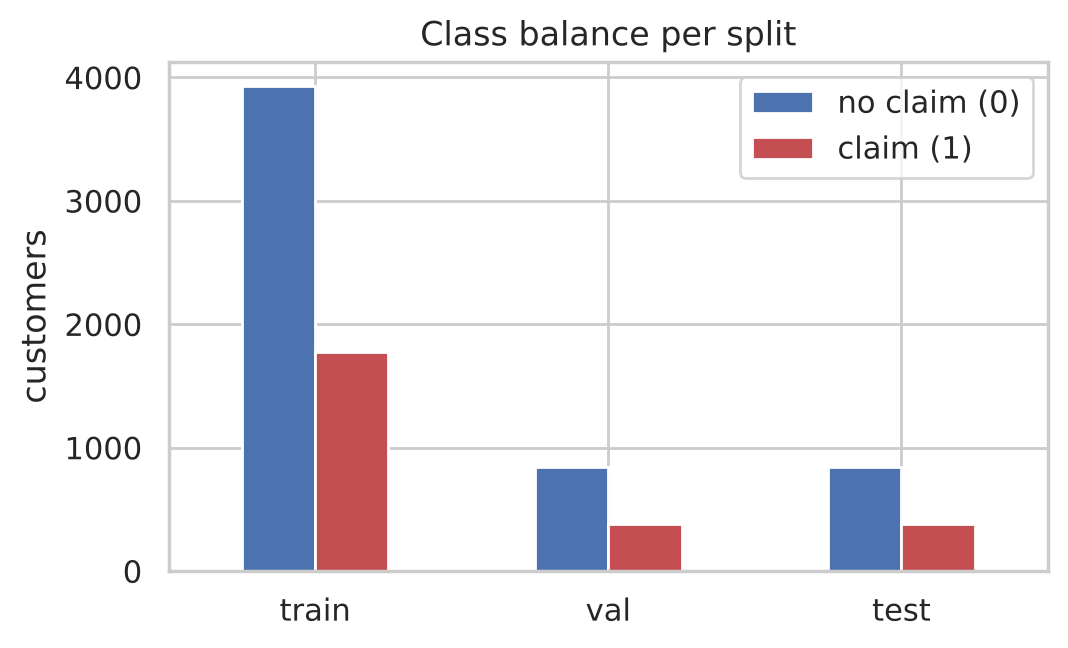

In [24]:
classes = np.array([0, 1])
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}      # computed on TRAIN only

counts = pd.DataFrame({s: np.bincount(y, minlength=2) for s, y in [("train", y_train), ("val", y_val), ("test", y_test)]},
                      index=["no claim (0)", "claim (1)"])
display(counts)

minority_share = y_train.mean() if y_train.mean() < 0.5 else 1 - y_train.mean()
print(f"Minority-class share (train): {minority_share:.1%}   |   imbalance ratio: {(1 - minority_share) / minority_share:.2f} : 1")
print("class_weight for model.fit(...):", {k: round(v, 3) for k, v in class_weight.items()})

fig, ax = plt.subplots(figsize=(5.5, 3.4))
counts.T.plot.bar(ax=ax, color=["#4C72B0", "#C44E52"], rot=0)
ax.set_title("Class balance per split"); ax.set_ylabel("customers")
savefig("06_class_balance.png")

**Reading this:** if the minority share is clearly below 50% (but not extreme), plain *accuracy* is misleading. Notebooks 02–03 should (a) pass `class_weight` from `data/processed/class_weights.json` to `model.fit`, and (b) judge models with Precision / Recall / F1 / ROC-AUC, as the README already requires. No resampling is applied: the validation and test sets keep the real class ratio.

## 3. Model Design
*From notebook 02.*

### 1. Load Splits

In [25]:
import json
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, accuracy_score

X_train, X_val, X_test, y_train, y_val, y_test = load_splits()

# Class weights computed in notebook 01 (claims are the minority class, ~31%)
with open(f"{PROCESSED_DIR}/class_weights.json") as f:
    CLASS_WEIGHT = {int(k): v for k, v in json.load(f).items()}

N_FEATURES = X_train.shape[1]
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Claim rate  train=%.3f  val=%.3f" % (y_train.mean(), y_val.mean()))
print("Class weights:", CLASS_WEIGHT)

# NOTE: the test set is NOT used in this notebook. It is reserved for final
# evaluation in notebook 03. All comparisons below use the validation set.

Train: (5703, 23) | Val: (1223, 23) | Test: (1223, 23)
Claim rate  train=0.311  val=0.312
Class weights: {0: 0.7257571901247136, 1: 1.6073844419391206}


### 2. Baseline ANN

**Design choices**
- **Input:** 23 features from notebook 01 (numeric columns already standardised, categorical columns encoded).
- **Hidden layers:** 2 Dense layers (64 → 32) with **ReLU**. That is enough capacity for ~5.7k training rows of tabular data; a deeper network would only overfit faster.
- **Output:** 1 neuron with **sigmoid**, which gives the claim probability (0–1).
- **Loss / optimizer:** binary cross-entropy with Adam (lr = 0.001).
- **Class imbalance:** only ~31% of customers claim, so we pass the `class_weight` from notebook 01. Without it the model under-predicts claims and recall drops.
- **Metrics tracked:** ROC-AUC (main metric, independent of the threshold), Precision and Recall.

`build_model()` takes `l2` and `dropout` arguments, so the baseline and the regularized model share **exactly the same architecture and starting weights**. The only difference between them is the regularization.

In [26]:
EPOCHS     = 150   # long on purpose: lets the baseline overfit so the effect is visible
BATCH_SIZE = 32
LR         = 1e-3

def build_model(units=(64, 32), l2=0.0, dropout=0.0, lr=LR, name="ann"):
    """Feed-forward ANN for binary classification.

    units   : neurons in each hidden layer
    l2      : L2 weight penalty on every hidden Dense layer (0 = off)
    dropout : dropout rate after every hidden layer (0 = off)
    """
    tf.keras.utils.set_random_seed(SEED)  # same initial weights for every run -> fair comparison
    reg = regularizers.l2(l2) if l2 > 0 else None

    model = keras.Sequential(name=name)
    model.add(keras.Input(shape=(N_FEATURES,)))
    for u in units:
        model.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))  # claim probability

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc"),
                 keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall")],
    )
    return model

baseline = build_model(name="baseline_ann")
baseline.summary()

Model: "baseline_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,649 (14.25 KB)

 Trainable params: 3,649 (14.25 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Train & Learning Curves

Baseline: lowest val_loss at epoch 11, final train_loss=0.134, val_loss=0.682


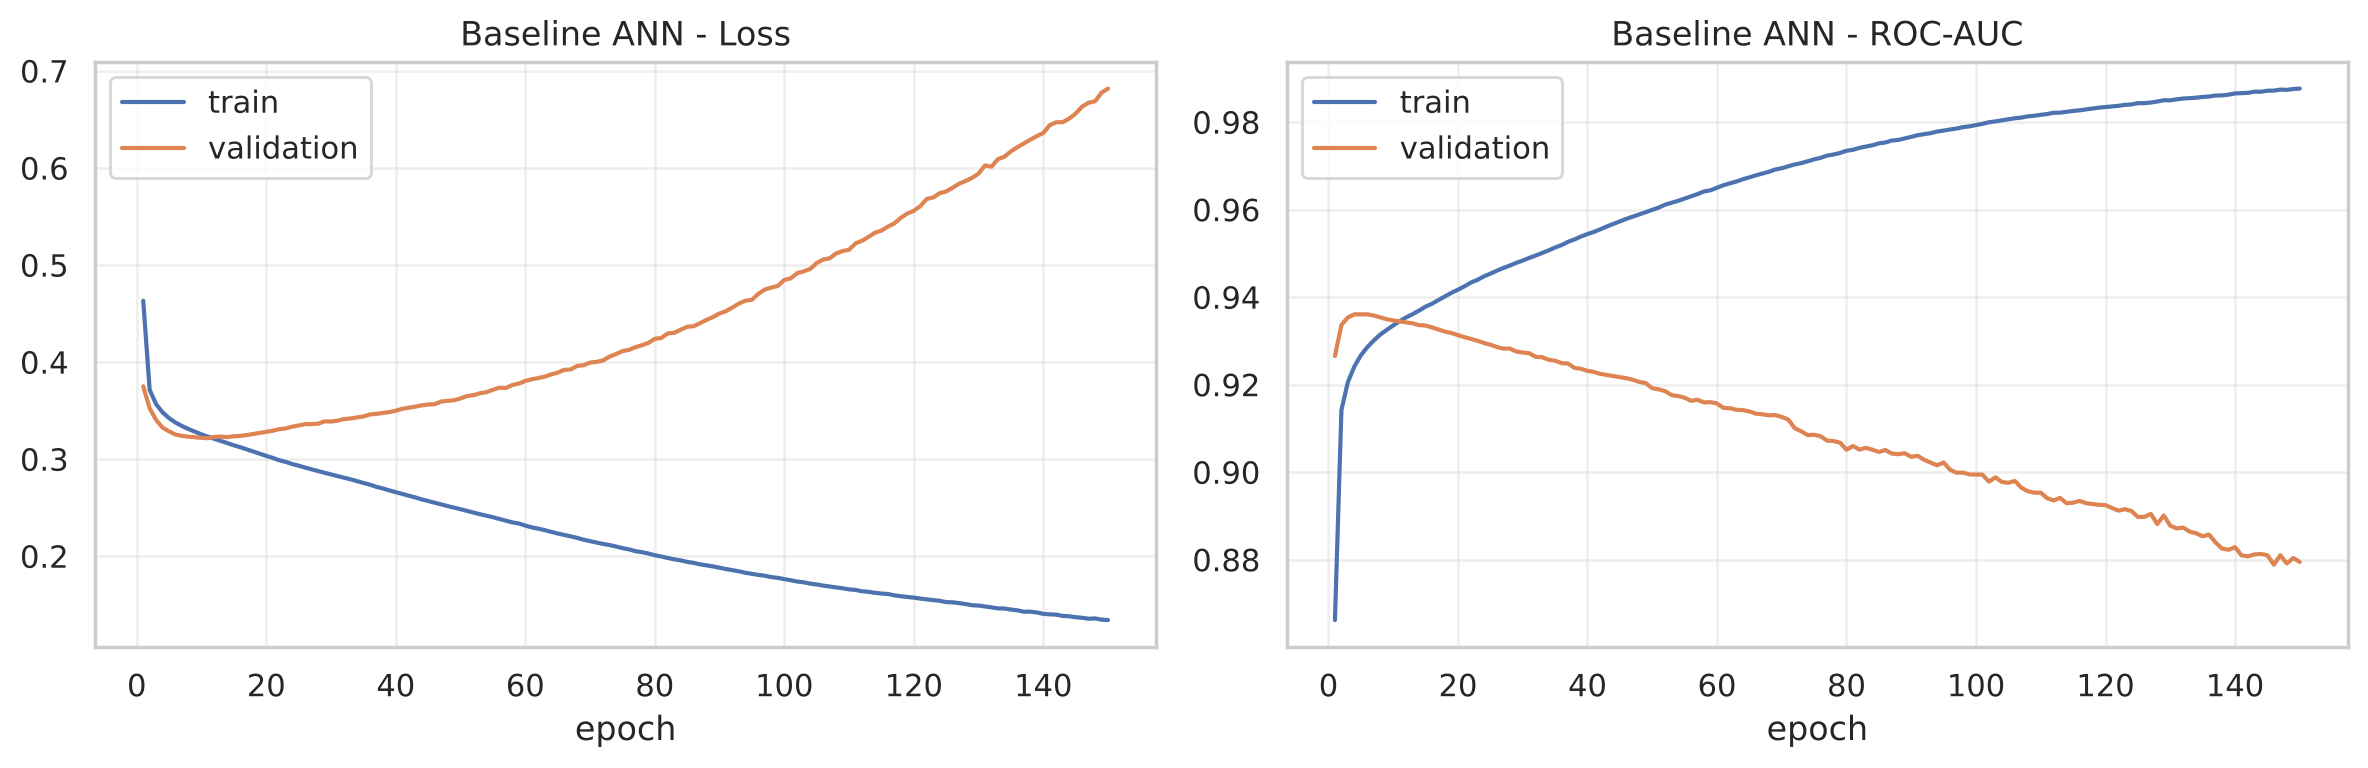

In [27]:
def train(model, callbacks=None, epochs=EPOCHS):
    return model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=BATCH_SIZE,
        class_weight=CLASS_WEIGHT,   # counter the class imbalance
        callbacks=callbacks or [], verbose=0,
    )

def plot_curves(history, title, ax_pair, stop_epoch=None):
    h = history.history
    ep = range(1, len(h["loss"]) + 1)
    for ax, metric, label in [(ax_pair[0], "loss", "Loss"), (ax_pair[1], "auc", "ROC-AUC")]:
        ax.plot(ep, h[metric], label="train")
        ax.plot(ep, h[f"val_{metric}"], label="validation")
        if stop_epoch:
            ax.axvline(stop_epoch, color="gray", ls="--", lw=1, label=f"best epoch ({stop_epoch})")
        ax.set_title(f"{title} - {label}"); ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)

hist_base = train(baseline)

best_ep = int(np.argmin(hist_base.history["val_loss"])) + 1
print(f"Baseline: lowest val_loss at epoch {best_ep}, "
      f"final train_loss={hist_base.history['loss'][-1]:.3f}, val_loss={hist_base.history['val_loss'][-1]:.3f}")

fig_base, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_curves(hist_base, "Baseline ANN", axes)
plt.tight_layout(); plt.show()

## 4. Regularization
*From notebook 02.*

### 4. Regularized ANN (L2, Dropout, EarlyStopping)

| Technique | Setting | What it does |
|---|---|---|
| **L2 (weight decay)** | λ = 0.001 on every hidden layer | Adds λ·Σw² to the loss, which keeps weights small so the model cannot fit noise with extreme weights |
| **Dropout** | rate = 0.3 after every hidden layer | Randomly switches off 30% of neurons on each training step, so the network cannot rely on any single neuron |
| **Early Stopping** | monitor `val_loss`, patience 15, `restore_best_weights=True` | Stops training once validation loss stops improving and rolls back to the best epoch |

To show what each technique contributes, we also train **L2 only** and **Dropout only** (no early stopping), then the **full combination**.

L2 only                    trained 150 epochs


Dropout only               trained 150 epochs


L2 + Dropout + EarlyStop   trained 56 epochs

EarlyStopping restored weights from epoch 41


Model: "l2__dropout__earlystop"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,949 (42.77 KB)

 Trainable params: 3,649 (14.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,300 (28.52 KB)

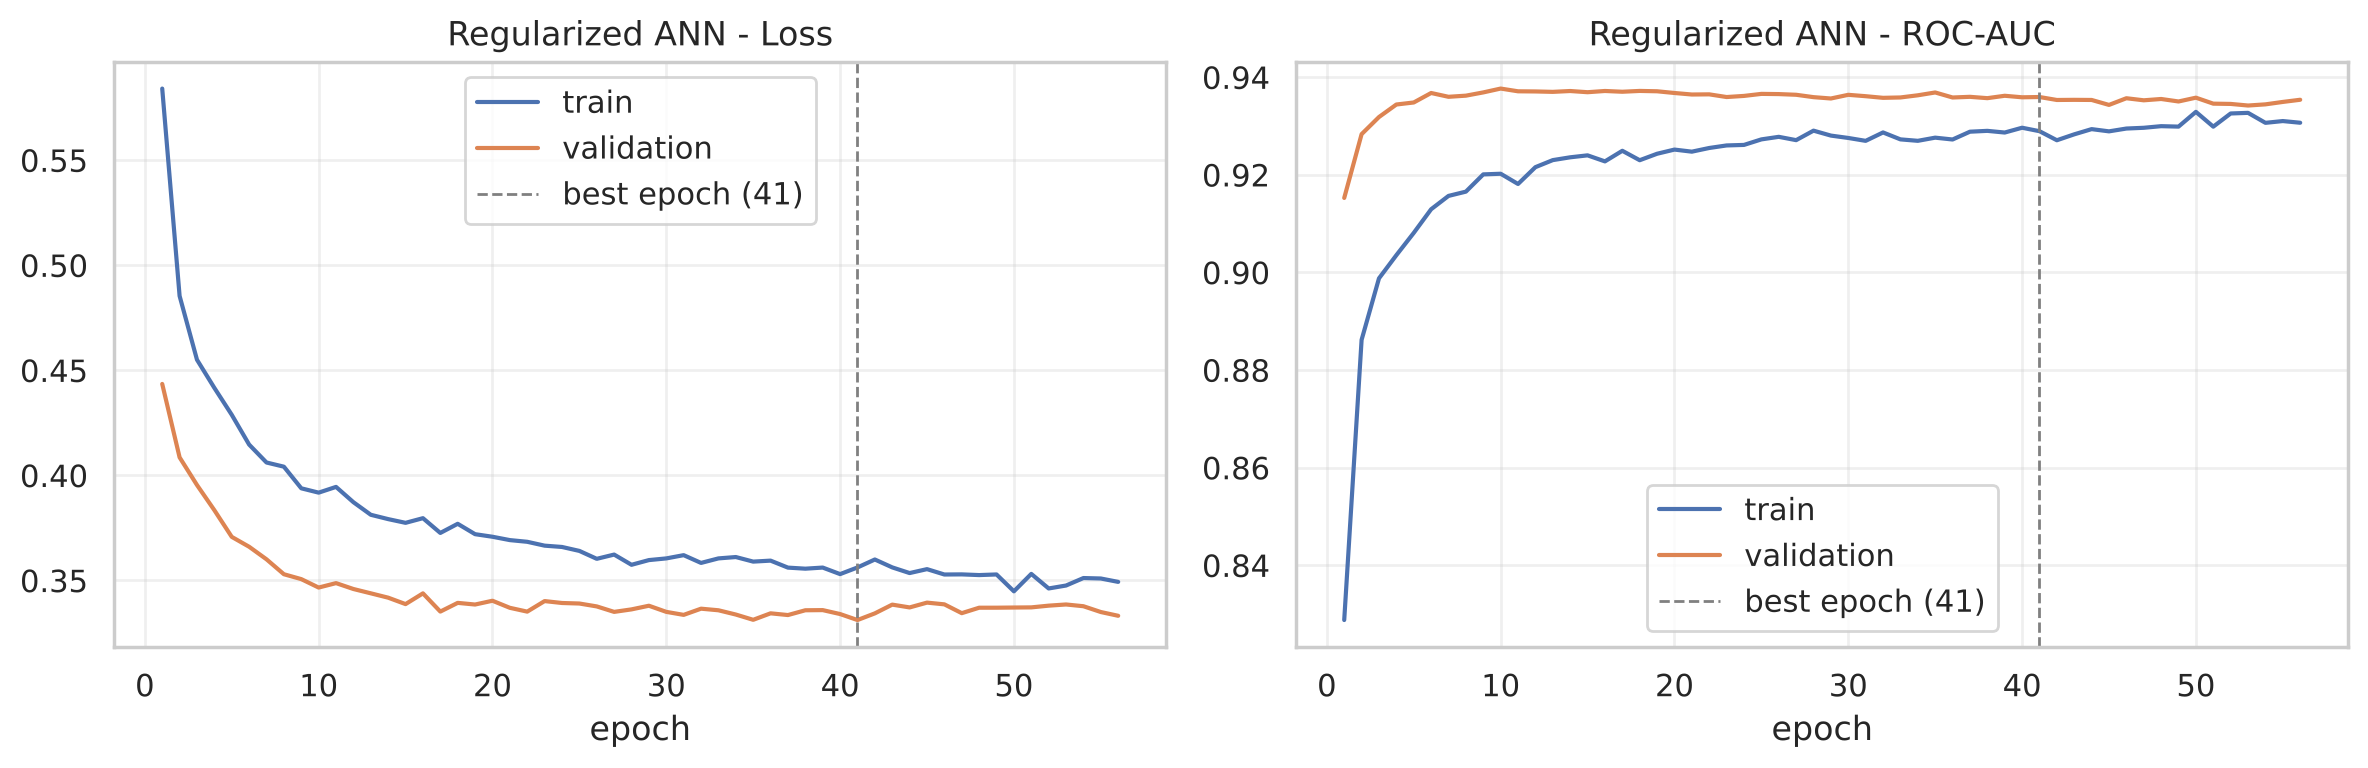

In [28]:
L2      = 1e-3
DROPOUT = 0.3

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True, verbose=0)

# Ablation: add each technique on its own, then all together, so we can see what each one does.
# L2-only and Dropout-only runs use no EarlyStopping (full EPOCHS) to isolate their effect.
experiments = {
    "L2 only":               dict(l2=L2,  dropout=0.0),
    "Dropout only":          dict(l2=0.0, dropout=DROPOUT),
    "L2 + Dropout + EarlyStop": dict(l2=L2, dropout=DROPOUT, early_stop=True),
}

models, histories = {"Baseline": baseline}, {"Baseline": hist_base}
for name, cfg in experiments.items():
    m = build_model(l2=cfg["l2"], dropout=cfg["dropout"], name=name.replace(" ", "_").replace("+", "").lower())
    histories[name] = train(m, callbacks=[early_stop] if cfg.get("early_stop") else None)
    models[name] = m
    print(f"{name:26s} trained {len(histories[name].history['loss'])} epochs")

regularized = models["L2 + Dropout + EarlyStop"]
hist_reg = histories["L2 + Dropout + EarlyStop"]
reg_best_ep = int(np.argmin(hist_reg.history["val_loss"])) + 1
print(f"\nEarlyStopping restored weights from epoch {reg_best_ep}")
regularized.summary()

fig_reg, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_curves(hist_reg, "Regularized ANN", axes, stop_epoch=reg_best_ep)
plt.tight_layout(); plt.show()

### 5. Baseline vs Regularized Comparison

#### Conclusions (validation set)

| Model | Precision | Recall | F1 | ROC-AUC | Train–Val AUC gap |
|---|---|---|---|---|---|
| Baseline | 0.697 | 0.774 | 0.734 | 0.889 | 0.099 |
| L2 only | 0.670 | 0.864 | 0.755 | 0.915 | 0.049 |
| Dropout only | 0.701 | 0.843 | 0.765 | 0.919 | 0.046 |
| **L2 + Dropout + EarlyStop** | **0.743** | 0.835 | **0.786** | **0.936** | **0.001** |

- **Every regularization technique helps.** L2 alone and Dropout alone each cut the overfitting gap roughly in half and raise validation ROC-AUC by ~0.03.
- **The combination works best.** It has the highest ROC-AUC (0.936), F1 (0.786) and precision, and the train–validation gap almost disappears (0.001). Early stopping ended training at epoch 56 and restored the weights from **epoch 41**.
- **Why validation loss is below training loss in the regularized curves:** dropout and the L2 penalty are active only during training, which makes training loss look worse. At evaluation time the full network is used without the penalty. This is expected, not a bug.
- **Hand-off to notebook 03:** the 64→32 network with L2 = 0.001, Dropout = 0.3 and EarlyStopping is the starting point for Keras Tuner. These settings are saved in `models/regularized_config.json`. The final test-set evaluation happens in notebook 03.

_Numbers come from the run with `SEED = 42`; small differences on another machine are normal._

,val_Accuracy,val_Precision,val_Recall,val_F1,val_ROC-AUC,train_AUC,AUC gap (train-val),min val_loss,final val_loss,epochs
Model,,,,,,,,,,
Baseline,0.8144,0.6734,0.7848,0.7248,0.8915,0.9877,0.0962,0.3215,0.6818,150
L2 only,0.8201,0.6613,0.8661,0.7500,0.9123,0.9649,0.0526,0.3483,0.4334,150
Dropout only,0.8463,0.7140,0.8451,0.7740,0.9203,0.9647,0.0444,0.3084,0.3626,150
L2 + Dropout + EarlyStop,0.8545,0.7355,0.8320,0.7808,0.9359,0.9371,0.0012,0.3312,0.3332,56


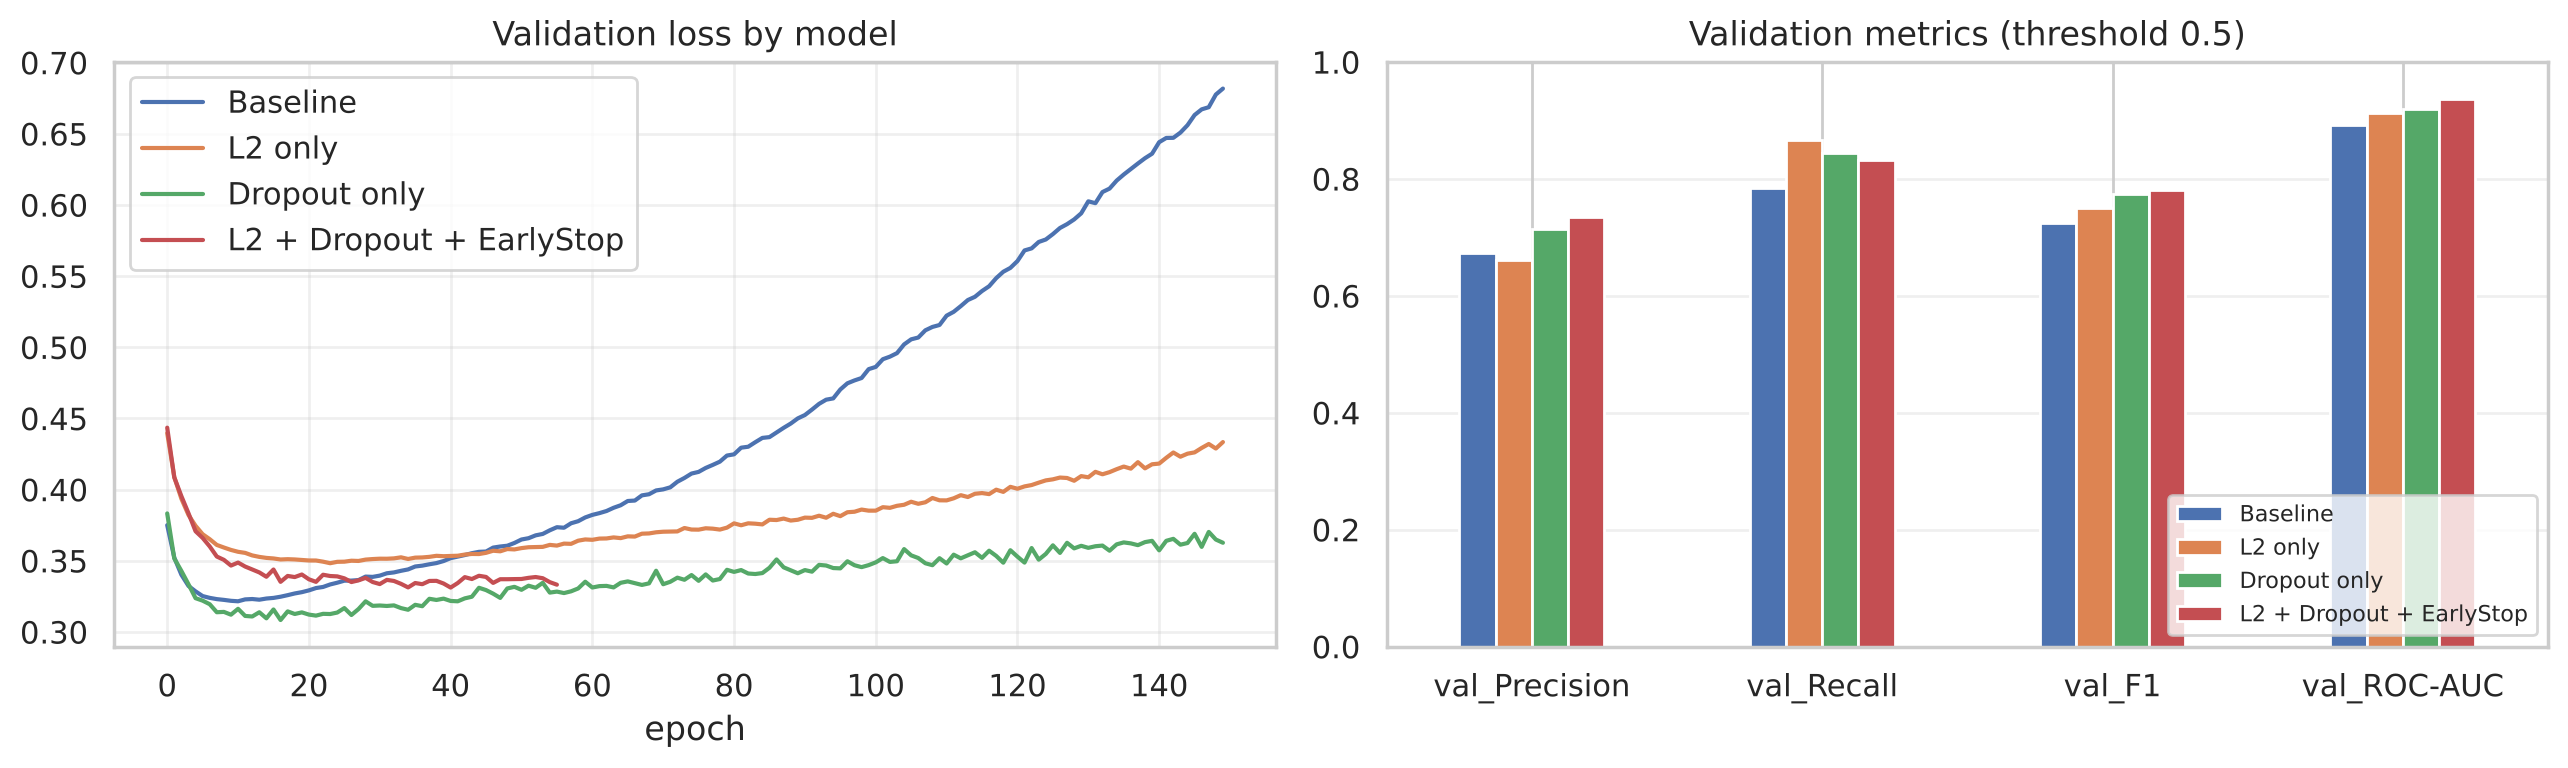

In [29]:
def evaluate(model, X, y, threshold=0.5):
    p = model.predict(X, verbose=0).ravel()
    yhat = (p >= threshold).astype(int)
    return {
        "Accuracy":  accuracy_score(y, yhat),
        "Precision": precision_score(y, yhat, zero_division=0),
        "Recall":    recall_score(y, yhat),
        "F1":        f1_score(y, yhat),
        "ROC-AUC":   roc_auc_score(y, p),
    }

rows = []
for name, m in models.items():
    tr, va = evaluate(m, X_train, y_train), evaluate(m, X_val, y_val)
    h = histories[name].history
    rows.append({"Model": name, **{f"val_{k}": v for k, v in va.items()},
                 "train_AUC": tr["ROC-AUC"],
                 "AUC gap (train-val)": tr["ROC-AUC"] - va["ROC-AUC"],
                 "min val_loss": min(h["val_loss"]),
                 "final val_loss": h["val_loss"][-1],
                 "epochs": len(h["loss"])})

comparison = pd.DataFrame(rows).set_index("Model").round(4)
display(comparison)

# Overlay: validation loss of every model on one plot
fig_cmp, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in histories.items():
    axes[0].plot(h.history["val_loss"], label=name)
axes[0].set_title("Validation loss by model"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=.3)

metrics = ["val_Precision", "val_Recall", "val_F1", "val_ROC-AUC"]
comparison[metrics].T.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Validation metrics (threshold 0.5)"); axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8, loc="lower right"); axes[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

## 5. Hyperparameter Tuning
*From notebook 03.*

### 1. Load Splits

In [30]:

import json
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras import layers, regularizers

import keras_tuner as kt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

# Load the frozen datasets from Member 1
X_train, X_val, X_test, y_train, y_val, y_test = load_splits()

# Load class weights
with open(f"{PROCESSED_DIR}/class_weights.json") as f:
    CLASS_WEIGHT = {int(k): float(v) for k, v in json.load(f).items()}

# Load Member 2's regularized model configuration
with open(f"{MODELS_DIR}/regularized_config.json") as f:
    REG_CONFIG = json.load(f)

N_FEATURES = X_train.shape[1]

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

print("\nNumber of features:", N_FEATURES)
print("Class weights:", CLASS_WEIGHT)
print("Starting configuration:", REG_CONFIG)


Training data: (5703, 23)
Validation data: (1223, 23)
Testing data: (1223, 23)

Number of features: 23
Class weights: {0: 0.7257571901247136, 1: 1.6073844419391206}
Starting configuration: {'units': [64, 32], 'l2': 0.001, 'dropout': 0.3, 'learning_rate': 0.001, 'batch_size': 32, 'early_stopping': {'monitor': 'val_loss', 'patience': 15}, 'best_epoch': 41}


### 2. Define `build_model(hp)`

In [31]:

def build_model(hp):

    model = keras.Sequential(name="tuned_ann")

    model.add(keras.Input(shape=(N_FEATURES,)))

    # First hidden layer
    units_1 = hp.Choice(
        "units_1",
        values=[32, 64, 128]
    )

    model.add(
        layers.Dense(
            units_1,
            activation="relu",
            kernel_regularizer=regularizers.l2(
                hp.Choice("l2", values=[0.0001, 0.001, 0.01])
            )
        )
    )

    # Second hidden layer
    units_2 = hp.Choice(
        "units_2",
        values=[16, 32, 64]
    )

    model.add(
        layers.Dense(
            units_2,
            activation="relu",
            kernel_regularizer=regularizers.l2(
                hp.get("l2")
            )
        )
    )

    # Dropout
    dropout = hp.Choice(
        "dropout",
        values=[0.2, 0.3, 0.4]
    )

    model.add(layers.Dropout(dropout))

    # Output layer
    model.add(layers.Dense(1, activation="sigmoid"))

    # Learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.0001, 0.001, 0.01]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall")
        ]
    )

    return model


### 3. Keras Tuner Search

In [32]:
RUN_TUNING = False   # True  = run the full Keras Tuner search again (~15 min, results can differ slightly)
                     # False = load the best model + hyperparameters that notebook 03 saved
if RUN_TUNING:
    tuner = kt.RandomSearch(
        hypermodel=build_model,
        objective=kt.Objective("val_auc", direction="max"),
        max_trials=20,
        executions_per_trial=1,
        directory="tuning_results",
        project_name="insurance_risk_tuning",
        overwrite=True,
        seed=SEED
    )
    early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    tuner.search(X_train, y_train, validation_data=(X_val, y_val), class_weight=CLASS_WEIGHT,
                 epochs=100, batch_size=32, callbacks=[early_stopping], verbose=1)
    best_hp_values = tuner.get_best_hyperparameters(num_trials=1)[0].values
    best_model = tuner.get_best_models(num_models=1)[0]
else:
    with open(f"{MODELS_DIR}/best_hyperparameters.json") as f:
        best_hp_values = json.load(f)
    best_model = keras.models.load_model(BEST_MODEL, compile=False)

print("Best Hyperparameters:")
for key, value in best_hp_values.items():
    print(f"  {key}: {value}")
best_model.summary()

Best Hyperparameters:
  units_1: 32
  l2: 0.01
  units_2: 64
  dropout: 0.4
  learning_rate: 0.01


Model: "tuned_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Evaluation
*From notebook 03.*

### 5. Test Evaluation (Precision, Recall, F1, ROC-AUC)

In [33]:

# Make predictions on the test dataset
y_prob = best_model.predict(
    X_test,
    verbose=0
).ravel()

# Convert probabilities into class predictions
y_pred = (y_prob >= 0.5).astype(int)


# Calculate evaluation metrics
test_results = {
    "Accuracy": accuracy_score(y_test, y_pred),

    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),

    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),

    "F1-Score": f1_score(
        y_test, y_pred, zero_division=0
    ),

    "ROC-AUC": roc_auc_score(y_test, y_prob)
}


# Display final evaluation results
print("Final Test Evaluation Results")
print("=" * 40)

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")


# Classification Report
print("\nClassification Report")
print("=" * 40)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Claim", "Claim"],
        zero_division=0
    )
)


Final Test Evaluation Results
Accuracy: 0.8201 (82.01%)
Precision: 0.6695 (66.95%)
Recall: 0.8346 (83.46%)
F1-Score: 0.7430 (74.30%)
ROC-AUC: 0.9027 (90.27%)

Classification Report
              precision    recall  f1-score   support

    No Claim       0.92      0.81      0.86       842
       Claim       0.67      0.83      0.74       381

    accuracy                           0.82      1223
   macro avg       0.79      0.82      0.80      1223
weighted avg       0.84      0.82      0.82      1223



### 6. Confusion Matrix & ROC Curve

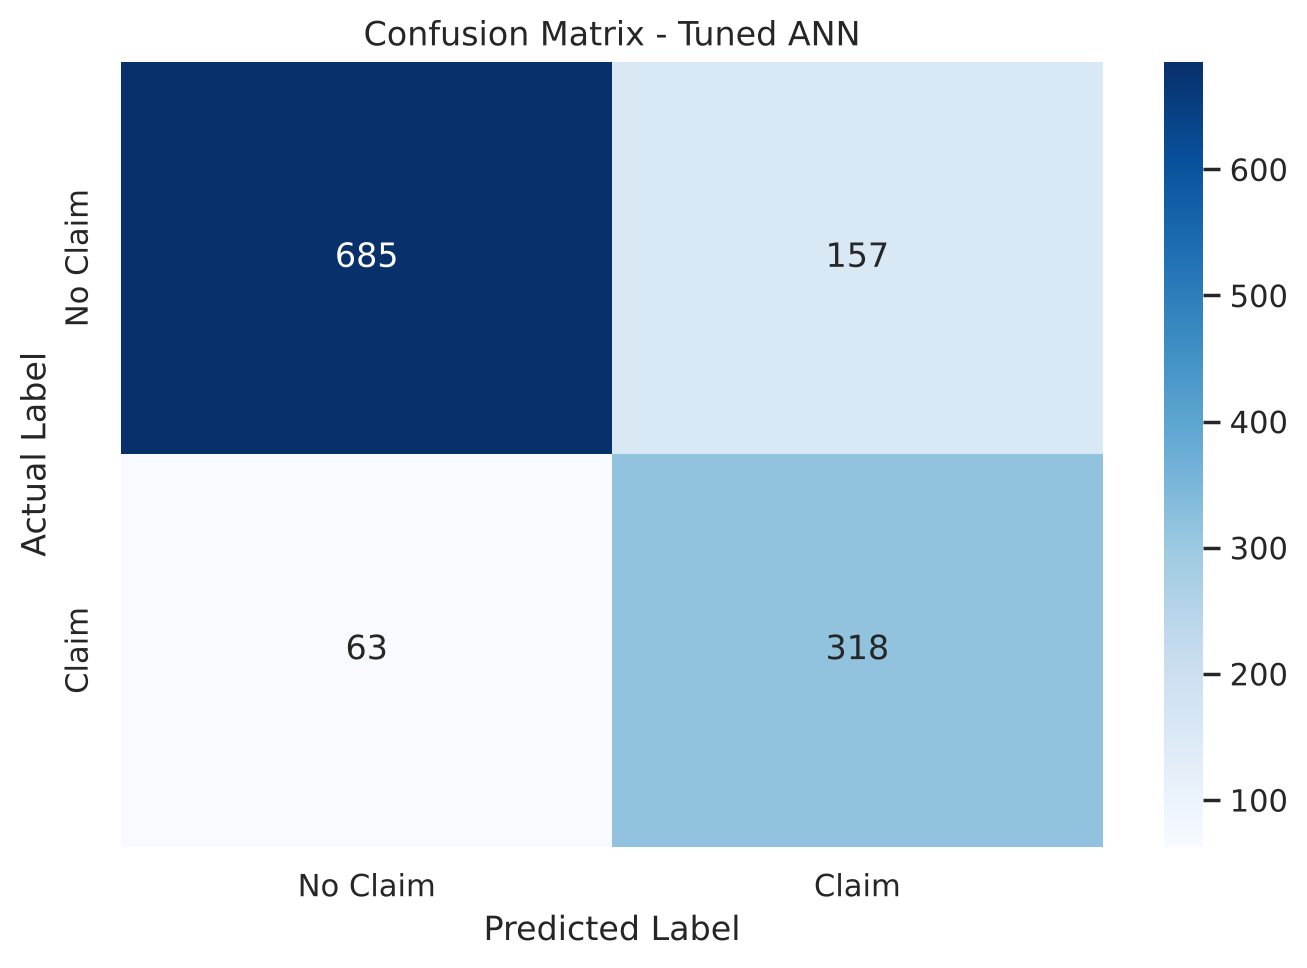

<Figure size 1400x1000 with 0 Axes>

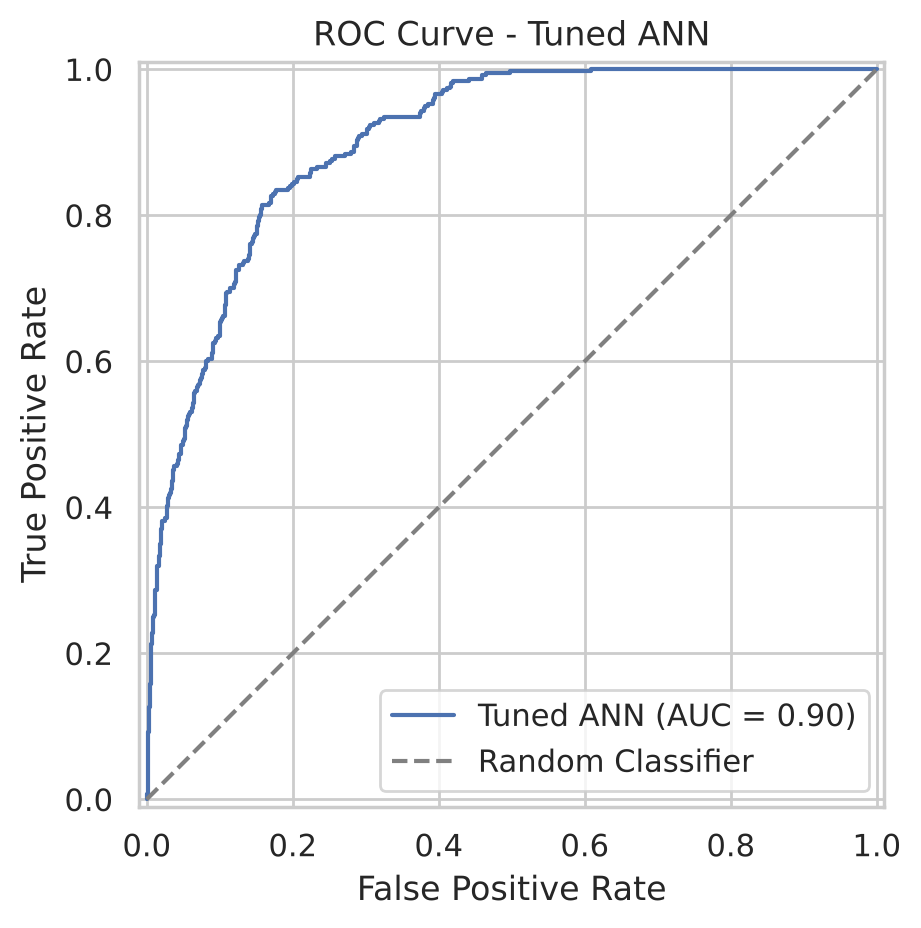

Confusion Matrix and ROC Curve generated successfully!


In [34]:
# Create figures directory if it does not exist
os.makedirs(FIGURES_DIR, exist_ok=True)


# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Claim", "Claim"],
    yticklabels=["No Claim", "Claim"]
)

plt.title("Confusion Matrix - Tuned ANN")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

# Save confusion matrix
plt.savefig(
    f"{FIGURES_DIR}/10_tuned_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 2. ROC Curve
plt.figure(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Tuned ANN"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curve - Tuned ANN")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()

# Save ROC curve
plt.savefig(
    f"{FIGURES_DIR}/11_tuned_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix and ROC Curve generated successfully!")

### 7. Error Analysis & Limitations

In [35]:
# 1. Identify incorrect predictions

errors = y_test != y_pred

false_positives = (y_test == 0) & (y_pred == 1)
false_negatives = (y_test == 1) & (y_pred == 0)

correct_predictions = (y_test == y_pred)

print("Error Analysis")
print("=" * 40)

print(f"Total Test Samples: {len(y_test)}")
print(f"Correct Predictions: {correct_predictions.sum()}")
print(f"Total Errors: {errors.sum()}")

print(f"\nFalse Positives: {false_positives.sum()}")
print(f"False Negatives: {false_negatives.sum()}")

print(
    f"\nError Rate: {errors.mean() * 100:.2f}%"
)


# 2. Calculate error percentages

print("\nError Percentages")
print("=" * 40)

print(
    f"False Positive Rate: "
    f"{false_positives.sum() / (y_test == 0).sum() * 100:.2f}%"
)

print(
    f"False Negative Rate: "
    f"{false_negatives.sum() / (y_test == 1).sum() * 100:.2f}%"
)


# 3. Display sample incorrect predictions

error_indices = np.where(errors)[0]

error_analysis = pd.DataFrame({
    "Actual": y_test[error_indices],
    "Predicted": y_pred[error_indices],
    "Predicted Probability": y_prob[error_indices]
})

error_analysis["Actual"] = error_analysis["Actual"].map({
    0: "No Claim",
    1: "Claim"
})

error_analysis["Predicted"] = error_analysis["Predicted"].map({
    0: "No Claim",
    1: "Claim"
})

print("\nSample Incorrect Predictions")
print("=" * 40)

display(error_analysis.head(10))

Error Analysis
Total Test Samples: 1223
Correct Predictions: 1003
Total Errors: 220

False Positives: 157
False Negatives: 63

Error Rate: 17.99%

Error Percentages
False Positive Rate: 18.65%
False Negative Rate: 16.54%

Sample Incorrect Predictions


,Actual,Predicted,Predicted Probability
0,No Claim,Claim,0.629759
1,Claim,No Claim,0.319011
2,No Claim,Claim,0.890732
3,Claim,No Claim,0.453113
4,No Claim,Claim,0.501923
5,Claim,No Claim,0.364040
6,Claim,No Claim,0.341975
7,No Claim,Claim,0.683162
8,Claim,No Claim,0.208866
9,No Claim,Claim,0.859490


## 7. Save & Load
*From notebook 04.*

### 1. Load Model & Preprocessor

In [36]:
# ===== Notebook-04 imports =====
import json, tempfile
import joblib
from tensorflow import keras
from sklearn.metrics import roc_auc_score, f1_score

# The final model = the TUNED model from notebook 03 (it had the best validation AUC)
model        = keras.models.load_model(BEST_MODEL, compile=False)   # compile=False: only needed for predicting
preprocessor = joblib.load(PREPROCESSOR_PKL)          # fitted on the training split in notebook 01

# Input rules written by notebook 01 (column names + allowed values)
with open(f"{PROCESSED_DIR}/preprocessor_meta.json") as f:
    META = json.load(f)
INPUT_COLS  = META["raw_input_columns"]
ALLOWED     = META["allowed_values"]
BINARY_COLS = META["column_groups"]["binary"]

print("Model loaded       :", BEST_MODEL, "| expects", model.input_shape[1], "features")
print("Preprocessor loaded:", PREPROCESSOR_PKL, "| takes", len(INPUT_COLS), "raw columns")
print("Raw input columns  :", INPUT_COLS)

Model loaded       : models/best_model.keras | expects 23 features
Preprocessor loaded: models/preprocessor.pkl | takes 17 raw columns
Raw input columns  : ['AGE', 'GENDER', 'RACE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'CREDIT_SCORE', 'VEHICLE_OWNERSHIP', 'VEHICLE_YEAR', 'MARRIED', 'CHILDREN', 'POSTAL_CODE', 'ANNUAL_MILEAGE', 'VEHICLE_TYPE', 'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS']


### 2. Save/Load Check (same predictions before & after)

In [37]:
X_train, X_val, X_test, y_train, y_val, y_test = load_splits()

# 1) The loaded model reproduces the test results that notebook 03 saved
p_loaded = model.predict(X_test, verbose=0).ravel()
with open(f"{MODELS_DIR}/test_evaluation_results.json") as f:
    saved = json.load(f)

auc_now = roc_auc_score(y_test, p_loaded)
f1_now  = f1_score(y_test, (p_loaded >= 0.5).astype(int))
print(f"ROC-AUC   saved in 03: {saved['ROC-AUC']:.4f} | after loading: {auc_now:.4f}")
print(f"F1-Score  saved in 03: {saved['F1-Score']:.4f} | after loading: {f1_now:.4f}")
assert abs(auc_now - saved["ROC-AUC"]) < 1e-3 and abs(f1_now - saved["F1-Score"]) < 1e-3

# 2) Save -> load again: predictions must be exactly the same
tmp_path = os.path.join(tempfile.gettempdir(), "reload_check.keras")
model.save(tmp_path)
reloaded   = keras.models.load_model(tmp_path, compile=False)
p_reloaded = reloaded.predict(X_test, verbose=0).ravel()
print("\nMax difference in predictions before vs after save/load:", np.abs(p_loaded - p_reloaded).max())
assert np.allclose(p_loaded, p_reloaded, atol=1e-6)

print("\nSave/load check passed.")

ROC-AUC   saved in 03: 0.9027 | after loading: 0.9027
F1-Score  saved in 03: 0.7430 | after loading: 0.7430



Max difference in predictions before vs after save/load: 0.0

Save/load check passed.


## 8. Inference Pipeline
*From notebook 04.*

### 3. `predict_risk(input_dict)` Function

In [38]:
THRESHOLD = 0.5   # same threshold used for the test evaluation in notebook 03

def predict_risk(input_dict, threshold=THRESHOLD):
    """Predict the claim probability for ONE customer.

    input_dict : raw values for the 17 columns in INPUT_COLS,
                 e.g. {"AGE": "16-25", "GENDER": "male", ..., "PAST_ACCIDENTS": 0}
    returns    : {"claim_probability": float, "prediction": int}   (1 = likely to claim)
    """
    # 1) Check the input (the preprocessor would silently accept wrong categories)
    missing = [c for c in INPUT_COLS if c not in input_dict]
    extra   = [c for c in input_dict if c not in INPUT_COLS]
    if missing or extra:
        raise ValueError(f"Missing columns: {missing} | Unknown columns: {extra}")

    row = {}
    for c in INPUT_COLS:
        v = input_dict[c]
        if isinstance(v, str):
            v = v.strip().lower()                    # same text cleaning as notebook 01
        if c in ALLOWED and v not in ALLOWED[c]:
            raise ValueError(f"{c}={v!r} is not allowed. Allowed values: {ALLOWED[c]}")
        if c in BINARY_COLS and v not in (0, 1):
            raise ValueError(f"{c} must be 0 or 1, got {v!r}")
        row[c] = v

    # 2) Same preprocessing as training  ->  3) model
    X = preprocessor.transform(pd.DataFrame([row], columns=INPUT_COLS)).astype("float32")
    prob = float(model.predict(X, verbose=0)[0, 0])
    return {"claim_probability": round(prob, 4), "prediction": int(prob >= threshold)}

### 4. Test on Sample Customers

In [39]:
# 1) Real customers from the test set: predict_risk() must give the same result as the model on X_test
raw = pd.read_csv(f"{PROCESSED_DIR}/splits_raw.csv")
test_raw = raw[raw["split"] == "test"].reset_index(drop=True)     # same row order as X_test

# 3 customers who did NOT claim + 3 who DID claim
sample_ids = list(test_raw.index[test_raw[TARGET] == 0][:3]) + list(test_raw.index[test_raw[TARGET] == 1][:3])

rows = []
for i in sample_ids:
    customer = test_raw.loc[i, INPUT_COLS].to_dict()
    result = predict_risk(customer)
    rows.append({"customer": i, "actual": int(test_raw.loc[i, TARGET]), **result,
                 "model_on_X_test": round(float(p_loaded[i]), 4)})
check = pd.DataFrame(rows)
display(check)
assert np.allclose(check["claim_probability"], check["model_on_X_test"], atol=1e-3)
print("predict_risk() matches the model on X_test for these customers.")

,customer,actual,claim_probability,prediction,model_on_X_test
0,0,0,0.0059,0,0.0059
1,1,0,0.0711,0,0.0711
2,2,0,0.0332,0,0.0332
3,10,1,0.3190,0,0.3190
4,13,1,0.6117,1,0.6117
5,18,1,0.4531,0,0.4531


predict_risk() matches the model on X_test for these customers.


In [40]:
# 2) Two made-up customers
low_risk = {
    "AGE": "40-64", "GENDER": "female", "RACE": "majority", "DRIVING_EXPERIENCE": "20-29y",
    "EDUCATION": "university", "INCOME": "upper class", "CREDIT_SCORE": 0.75,
    "VEHICLE_OWNERSHIP": 1, "VEHICLE_YEAR": "after 2015", "MARRIED": 1, "CHILDREN": 1,
    "POSTAL_CODE": 10238, "ANNUAL_MILEAGE": 10000, "VEHICLE_TYPE": "sedan",
    "SPEEDING_VIOLATIONS": 0, "DUIS": 0, "PAST_ACCIDENTS": 0,
}
# Same customer, but young, new driver, low income, doesn't own the car, older vehicle, more mileage
high_risk = {**low_risk, "AGE": "16-25", "DRIVING_EXPERIENCE": "0-9y", "INCOME": "poverty",
             "CREDIT_SCORE": 0.30, "VEHICLE_OWNERSHIP": 0, "VEHICLE_YEAR": "before 2015",
             "MARRIED": 0, "CHILDREN": 0, "ANNUAL_MILEAGE": 18000}

for name, customer in [("Low-risk customer ", low_risk), ("High-risk customer", high_risk)]:
    print(name, "->", predict_risk(customer))

Low-risk customer  -> {'claim_probability': 0.0094, 'prediction': 0}
High-risk customer -> {'claim_probability': 0.9053, 'prediction': 1}


In [41]:
# 3) Wrong input is rejected with a clear message
try:
    predict_risk({**low_risk, "AGE": "30"})
except ValueError as e:
    print("Rejected:", e)

Rejected: AGE='30' is not allowed. Allowed values: ['16-25', '26-39', '40-64', '65+']


#### Summary
- `best_model.keras` (tuned model from notebook 03) and `preprocessor.pkl` (notebook 01) load correctly and reproduce the saved test results.
- Saving and loading again gives identical predictions.
- `predict_risk()` takes one customer's raw values, checks them, applies the **same** preprocessing as training, and returns the claim probability + 0/1 prediction (threshold 0.5).

## 9. Results & Limitations

In [42]:
# Test-set results of the three saved models (threshold 0.5)
from sklearn.metrics import precision_score, recall_score

results = []
for name, path in [("Baseline ANN", "baseline_model.keras"),
                   ("Regularized ANN (02)", "regularized_model.keras"),
                   ("Tuned ANN (03) - final", "best_model.keras")]:
    m = keras.models.load_model(f"{MODELS_DIR}/{path}", compile=False)
    p = m.predict(X_test, verbose=0).ravel()
    yhat = (p >= 0.5).astype(int)
    results.append({"Model": name,
                    "Precision": precision_score(y_test, yhat), "Recall": recall_score(y_test, yhat),
                    "F1": f1_score(y_test, yhat), "ROC-AUC": roc_auc_score(y_test, p)})
pd.DataFrame(results).set_index("Model").round(3)

,Precision,Recall,F1,ROC-AUC
Model,,,,
Baseline ANN,0.644,0.740,0.689,0.862
Regularized ANN (02),0.693,0.819,0.751,0.907
Tuned ANN (03) - final,0.669,0.835,0.743,0.903


### Results (test set, 1,223 customers)

| Model | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Baseline ANN | 0.644 | 0.740 | 0.689 | 0.862 |
| Regularized ANN (L2 + Dropout + EarlyStopping) | 0.693 | 0.819 | 0.751 | 0.907 |
| **Tuned ANN (final model)** | 0.669 | 0.835 | 0.743 | 0.903 |

- **Regularization gave the big improvement:** ROC-AUC 0.862 → 0.907 on test, and the train–validation gap almost disappeared.
- **Tuning matched the regularized model but did not beat it on test.** The tuned model was chosen because it had the best **validation** AUC (0.939). Choosing by the test score instead would be leakage. The test difference (0.903 vs 0.907) is within noise for 1,223 rows.
- The final model catches **83% of real claimers** (recall). The price is more false alarms: 157 of 842 non-claimers are flagged.

### Limitations
- **Missing values:** 18.5% of rows were dropped. The claim rate did not change (31.3% → 31.1%), but the model learned from less data. Imputation could keep these rows.
- **Fixed threshold (0.5):** with class weights the model favours recall over precision. An insurer could move the threshold depending on the cost of a missed claim vs. a false alarm.
- **Small data, one split, one seed:** validation → test drops ~0.03 AUC for every model. Cross-validation would give a more reliable estimate.
- **Sensitive features:** `RACE` and `GENDER` are used as inputs. Using them may be unfair or not allowed for real insurance pricing.
- **Feature definitions:** `PAST_ACCIDENTS`, `SPEEDING_VIOLATIONS` and `DUIS` must be history *before* the policy started, otherwise they leak the outcome. The dataset doesn't document this.
- **Dataset:** Kaggle data with unclear origin. Some patterns are unrealistic (more speeding violations ↔ fewer claims), so results may not transfer to real customers.